# Childhood Pneumonia Prediction — Comparative ML Framework


## 1. Setup & Imports

In [ ]:
!pip install xgboost lightgbm shap imbalanced-learn scikit-learn matplotlib seaborn openpyxl -q

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
import json, os
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                      RandomizedSearchCV, train_test_split)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve,
                              confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import randint, uniform, mannwhitneyu, chi2_contingency

os.makedirs('figs', exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
print("Libraries loaded successfully.")
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from scipy import stats
import inspect

from sklearn.base import clone
from sklearn.preprocessing import MinMaxScaler
import sklearn, imblearn, xgboost, lightgbm, scipy, platform, sys

QUICK = False            # True = smoke test only (tiny search, few bootstraps). FINAL RUN MUST BE False.
SEED = 42
N_BOOT = 200 if QUICK else 2000
os.makedirs('results', exist_ok=True)
VERSIONS = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__,
                pandas=pd.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__,
                imblearn=imblearn.__version__, xgboost=xgboost.__version__, lightgbm=lightgbm.__version__,
                shap=shap.__version__)
print(VERSIONS)

# ---- shared helpers -------------------------------------------------------
def bootstrap_auc_ci(y_true, y_prob, n_boot=None, seed=SEED):
    """Stratified percentile bootstrap 95% CI for AUC."""
    n_boot = n_boot or N_BOOT
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    if len(pos) < 2 or len(neg) < 2: return (np.nan, np.nan)
    v = []
    for _ in range(n_boot):
        ii = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        v.append(roc_auc_score(y_true[ii], y_prob[ii]))
    return tuple(np.percentile(v, [2.5, 97.5]))

def cv_summary(scores):
    """mean, SD (ddof=1) and t-based 95% CI of the MEAN over folds (folds are correlated: approximate)."""
    s = np.asarray(scores, dtype=float); k = len(s); sd = s.std(ddof=1)
    half = stats.t.ppf(0.975, k - 1) * sd / np.sqrt(k)
    return dict(mean=s.mean(), sd=sd, ci_low=s.mean() - half, ci_high=s.mean() + half, half=half)

def save(df, name):
    df.to_csv(f'results/{name}.csv', index=False); return df

Libraries loaded successfully.
{'python': '3.13.16', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'imblearn': '0.14.2', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'shap': '0.52.0'}


## 2. Load Data & Engineer Features

We load the raw clinical dataset and construct the target variable plus 28 predictive
features spanning four categories: **Clinical biomarkers**, **Demographic variables**,
**Socio-environmental determinants**, and **Vaccination history**.

In [ ]:
def resolve_data_path():
    env_path = os.environ.get('BD_IRA_PATH')
    candidates = [env_path] if env_path else []
    root = Path.cwd()
    candidates.extend([
        root / 'BD IRA.xlsx',
        root / 'BD_IRA.xlsx',
        root / 'Data' / 'BD IRA.xlsx',
        root / 'Data' / 'BD_IRA.xlsx',
    ])

    seen = set()
    for candidate in candidates:
        if candidate is None:
            continue
        path = Path(candidate).expanduser()
        if str(path) in seen:
            continue
        seen.add(str(path))
        if path.exists():
            return str(path)

    current = root
    for _ in range(6):
        for name in ['BD IRA.xlsx', 'BD_IRA.xlsx']:
            for candidate in [current / name, current / 'Data' / name]:
                if candidate.exists():
                    return str(candidate)
        current = current.parent

    raise FileNotFoundError(
        "Could not find the BD IRA Excel file. Set BD_IRA_PATH to the correct file or place the workbook in the repo root or Data/ folder."
    )

DATA_PATH = resolve_data_path()
df = pd.read_excel(DATA_PATH)
print('Raw shape:', df.shape)
df.head()


Raw shape: (801, 91)


,ID PATIENT,Admission date,Age (months),Gender,Medical insurance,Length of stay (Days),Meets criteria for clinical pneumonia,Number of persons living in house,Number of siblings,Number of rooms in house,...,HIV testing,HIV test results,Blood culture results,Nasopharyngeal aspirate culture (NPA) Identification 1,Nasopharyngeal aspirate culture (NPA) Identification 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 1,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 3,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 4,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 5
0,PN0001,2010-11-02,41,Male,No,57,Yes,5.0,3.0,1.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
1,PN0002,2010-11-02,56,Female,No,3,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,Parainfluenza viruses 3,Parainfluenza viruses 1,Adenovirus,Rhinovirus,N/A
2,PN0003,2010-11-03,26,Male,Yes,12,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,CoronavirusesNL63,NaN,N/A,N/A,N/A
3,PN0004,2010-11-04,2,Male,No,22,Yes,7.0,4.0,1.0,...,No,NaN,Pseudomonas oryzihabitans,Negative,NaN,RSV-B,Parainfluenza viruses 3,Rhinovirus,N/A,N/A
4,PN0005,2010-11-05,15,Male,No,7,Yes,5.0,3.0,2.0,...,No,NaN,Negative,Negative,NaN,Adenovirus,NaN,N/A,N/A,N/A


In [ ]:
# ── Target variable: pneumonia-positive diagnoses ──────────────────────────
pneumonia_diags = ['Pneumonia', 'Dyspneic pneumopathy', 'Staphylococcal pneumonia',
                   'Bronchiolitis + Pneumonia', 'Asthma attack + Pneumonia',
                   'Pleuropneumonitis', 'Interstitial pneumopathy']
df['target'] = df['Main diagnostic '].isin(pneumonia_diags).astype(int)

print(df['target'].value_counts())
print(f"Positive (pneumonia) rate: {df['target'].mean():.1%}")

target
0    582
1    219
Name: count, dtype: int64
Positive (pneumonia) rate: 27.3%


In [ ]:
# ── Helper: convert Yes/No columns to binary ────────────────────────────────
def yn(col):
    return (df[col].str.strip().str.lower() == 'yes').astype(int)

feat = pd.DataFrame()

# --- Clinical biomarkers ---
feat['CRP']             = pd.to_numeric(df['C-reactive protein'], errors='coerce')
feat['Procalcitonin']   = pd.to_numeric(df['Procalcitonin'], errors='coerce')
feat['SaO2']            = pd.to_numeric(df['Oxygen saturation (SaO2) at admission'], errors='coerce')
feat['Temperature']     = pd.to_numeric(df['Axillary temperature (\u00b0C)'], errors='coerce')
feat['RespiratoryRate'] = pd.to_numeric(df['Respiratory rate'], errors='coerce')
feat['HeartRate']       = pd.to_numeric(df['Heart rate'], errors='coerce')

# --- Clinical signs ---
feat['Fever']        = yn('History of fever')
feat['Crackles']     = yn('Crackles')
feat['Wheezing']     = yn('Wheezing')
feat['NasalFlaring'] = yn('Nasal flaring')
feat['Cyanosis']     = yn('Cyanosis')

# --- Demographic ---
feat['Age']          = df['Age (months)'].astype(float)
feat['Gender']       = (df['Gender '].str.strip() == 'Male').astype(int)
feat['Siblings']     = pd.to_numeric(df['Number of siblings'], errors='coerce')
feat['Prematurity']  = yn('Health history : Prematurity                      ')
feat['Breastfed']    = yn('Breastfeeding')
feat['PriorRespAdm'] = yn('Health history : Prior admission because of respiratory condition')

# --- Socio-environmental (KEY research variables) ---
feat['HouseholdSize']  = pd.to_numeric(df['Number of persons living in house'], errors='coerce')
feat['Rooms']          = pd.to_numeric(df['Number of rooms in house'], errors='coerce')
feat['PersonsPerRoom'] = feat['HouseholdSize'] / feat['Rooms'].replace(0, np.nan)
feat['SmokersAtHome']  = yn('Smokers at home')
feat['VitaminA']       = yn('Vitamin A supplementation ')

# --- Vaccination (one-hot + dose counts) ---
vax = df['Age-appropriate vaccinations'].str.strip()
feat['Vacc_Full']    = (vax == 'Yes').astype(int)
feat['Vacc_Partial'] = (vax == 'Partially').astype(int)
feat['Vacc_None']    = (vax == 'No').astype(int)
feat['HibDoses']     = pd.to_numeric(df['Number of Hib vaccine doses received'], errors='coerce')
feat['PneumoDoses']  = pd.to_numeric(df['Number of pneumococcal vaccine doses received'], errors='coerce')

# --- Chest X-ray (ordinal encode) ---
xray_map = {'Normal': 0, 'NF': 1, 'Other infiltrates': 2, 'Endpoint pneumonia': 3}
feat['ChestXray'] = df['Chest X-ray finding'].map(xray_map)

feat['target'] = df['target'].values

print(f"Engineered {feat.shape[1]-1} features.")
feat.head()

Engineered 28 features.


,CRP,Procalcitonin,SaO2,Temperature,RespiratoryRate,HeartRate,Fever,Crackles,Wheezing,NasalFlaring,...,PersonsPerRoom,SmokersAtHome,VitaminA,Vacc_Full,Vacc_Partial,Vacc_None,HibDoses,PneumoDoses,ChestXray,target
0,79.0,1.35,80.0,37.8,72.0,143.0,1,0,0,1,...,5.0,1,1,1,0,0,3,0,3.0,1
1,46.0,0.10,91.0,38.0,84.0,142.0,1,0,1,1,...,3.0,1,1,1,0,0,3,0,1.0,0
2,4.0,0.10,99.0,37.6,60.0,130.0,0,0,1,1,...,3.0,1,1,1,0,0,3,1,NaN,0
3,5.0,0.06,84.0,36.8,90.0,135.0,0,0,1,0,...,7.0,1,0,0,1,0,1,0,3.0,0
4,2.0,0.09,93.0,38.5,60.0,144.0,1,0,1,0,...,2.5,0,1,1,0,0,3,0,0.0,0


In [ ]:
# Exclusion only (no statistics are computed from the data here). Imputation happens INSIDE the pipelines.
CRITICAL = ['CRP', 'Age', 'RespiratoryRate', 'HouseholdSize']
FEATURE_COLS = [c for c in feat.columns if c != 'target']
miss = pd.DataFrame({'n_missing': feat[FEATURE_COLS].isna().sum(),
                     'pct_missing': (feat[FEATURE_COLS].isna().mean() * 100).round(2)}).reset_index().rename(columns={'index': 'feature'})
save(miss, 'table_missing_data_before_exclusion')
n_before = len(feat)
feat = feat.dropna(subset=CRITICAL + ['target']).copy()
X = feat[FEATURE_COLS].copy()          # DataFrame, original index kept
y = feat['target'].values

print(f"Records: {n_before} -> {len(feat)} (excluded {n_before - len(feat)} missing {CRITICAL})")
print(f"Features: {len(FEATURE_COLS)} | class counts: {dict(feat['target'].value_counts())} | positive rate {feat['target'].mean():.3f}")
print("Predictor cells still missing (imputed in-pipeline):", int(X.isna().sum().sum()))

Records: 801 -> 799 (excluded 2 missing ['CRP', 'Age', 'RespiratoryRate', 'HouseholdSize'])
Features: 28 | class counts: {0: np.int64(581), 1: np.int64(218)} | positive rate 0.273
Predictor cells still missing (imputed in-pipeline): 129


## 3. Train-Test Split

One stratified 80/20 split (seed 42). Imputation, scaling and SMOTE are fitted inside pipelines on training data only; the test set is used once for final evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
SPLIT = dict(n_train=len(y_train), n_test=len(y_test), train_pos=int(y_train.sum()), train_neg=int((y_train == 0).sum()),
             test_pos=int(y_test.sum()), test_neg=int((y_test == 0).sum()))
print(SPLIT)
save(pd.DataFrame([SPLIT]), 'table_split_counts')

{'n_train': 639, 'n_test': 160, 'train_pos': 174, 'train_neg': 465, 'test_pos': 44, 'test_neg': 116}


,n_train,n_test,train_pos,train_neg,test_pos,test_neg
0,639,160,174,465,44,116


## 4. Hyperparameter Tuning (XGBoost, LightGBM, Logistic Regression, Random Forest)

`RandomizedSearchCV` (ROC-AUC, 5-fold stratified CV). Pipeline: median imputation -> StandardScaler -> SMOTE -> classifier, so every step is fitted inside each training fold.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)          # tuning folds
cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)  # nested / reporting folds

def make_pipe(clf):
    return ImbPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=SEED)),
        ('clf', clf)
    ])

def tune(name, est, param_dist, X_tr, y_tr, n_iter=30):
    pipe = make_pipe(est)
    param_dist_prefixed = {'clf__' + k: v for k, v in param_dist.items()}
    rs = RandomizedSearchCV(pipe, param_dist_prefixed, n_iter=3 if QUICK else n_iter,
                            scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=-1, return_train_score=False)
    rs.fit(X_tr, y_tr)
    print(f"{name}: tuning-CV AUC (optimistic, same folds used to choose params) = {rs.best_score_:.4f}")
    print(f"  Best params: {rs.best_params_}")
    return rs.best_estimator_, rs.best_score_, rs

In [ ]:
# --- XGBoost tuning ---
xgb_params = {
    'n_estimators': randint(100, 400),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
}
xgb_best, xgb_cv, xgb_search = tune('XGBoost', XGBClassifier(random_state=SEED, eval_metric='logloss', verbosity=0),
                                    xgb_params, X_train, y_train, n_iter=40)

XGBoost: tuning-CV AUC (optimistic, same folds used to choose params) = 0.8796
  Best params: {'clf__colsample_bytree': np.float64(0.610167650697638), 'clf__learning_rate': np.float64(0.031578285398660894), 'clf__max_depth': 3, 'clf__n_estimators': 151, 'clf__subsample': np.float64(0.8253102287905535)}


In [ ]:
# --- LightGBM tuning ---
lgb_params = {
    'n_estimators': randint(100, 400),
    'num_leaves': randint(20, 80),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_samples': randint(5, 30),
}
lgb_best, lgb_cv, lgb_search = tune('LightGBM', LGBMClassifier(random_state=42, verbose=-1),
                                    lgb_params, X_train, y_train, n_iter=40)


LightGBM: tuning-CV AUC (optimistic, same folds used to choose params) = 0.8771
  Best params: {'clf__colsample_bytree': np.float64(0.662397808134481), 'clf__learning_rate': np.float64(0.021616722433639893), 'clf__min_child_samples': 28, 'clf__n_estimators': 199, 'clf__num_leaves': 59, 'clf__subsample': np.float64(0.8832290311184181)}


In [ ]:
# --- Logistic Regression tuning ---
lr_params = {
    'C': uniform(0.01, 10),
    'solver': ['lbfgs', 'saga'],
    'max_iter': [500, 1000],
}
lr_best, lr_cv, lr_search = tune('Logistic Regression', LogisticRegression(random_state=42),
                                 lr_params, X_train, y_train, n_iter=20)

# --- Random Forest tuning (added for fair comparison with the strongest baseline) ---
rf_params = {
    'n_estimators': randint(100, 401),
    'max_depth': [None, 5, 8, 10, 12, 15],
    'min_samples_split': randint(2, 11),
    'min_samples_leaf': randint(1, 6),
    'max_features': ['sqrt', 'log2', None],
}
rf_best, rf_cv, rf_search = tune('Random Forest', RandomForestClassifier(random_state=42, n_jobs=-1),
                                  rf_params, X_train, y_train, n_iter=40)


Logistic Regression: tuning-CV AUC (optimistic, same folds used to choose params) = 0.8738
  Best params: {'clf__C': np.float64(0.21584494295802448), 'clf__max_iter': 1000, 'clf__solver': 'saga'}
Random Forest: tuning-CV AUC (optimistic, same folds used to choose params) = 0.8865
  Best params: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 8, 'clf__n_estimators': 161}


## 5. Evaluate All 11 Models

For tuned models the CV-AUC is **nested** (the whole search is repeated inside each outer fold); untuned models use the same outer folds. Final metrics are on the untouched test set.

In [ ]:
models = {
    'Logistic Regression (Tuned)': lr_best,
    'Decision Tree':       make_pipe(DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)),
    'Random Forest (Tuned)': rf_best,
    'Gradient Boosting':   make_pipe(GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42)),
    'AdaBoost':            make_pipe(AdaBoostClassifier(n_estimators=100, random_state=42)),
    'XGBoost (Tuned)':     xgb_best,
    'LightGBM (Tuned)':    lgb_best,
    'SVM (RBF)':           make_pipe(SVC(kernel='rbf', probability=True, random_state=42)),
    'KNN (k=7)':           make_pipe(KNeighborsClassifier(n_neighbors=7)),
    'Naive Bayes':         make_pipe(GaussianNB()),
    'MLP (100,50)':        make_pipe(MLPClassifier(hidden_layer_sizes=(100,50), max_iter=500, random_state=42)),
}
print(f"{len(models)} models configured.")

# Search objects, used for NESTED CV of the tuned models.
SEARCHES = {'Logistic Regression (Tuned)': lr_search, 'Random Forest (Tuned)': rf_search,
            'XGBoost (Tuned)': xgb_search, 'LightGBM (Tuned)': lgb_search}

11 models configured.


In [ ]:
results = {}
cv_scores_all = {}

for name, pipe in models.items():
    # Nested CV for tuned models (search repeated inside every outer training fold); plain CV otherwise.
    if name in SEARCHES:
        cv_auc = cross_val_score(clone(SEARCHES[name]), X_train, y_train, cv=cv_outer, scoring='roc_auc', n_jobs=1)
        cv_type, tuning_auc = 'nested', SEARCHES[name].best_score_
    else:
        cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv_outer, scoring='roc_auc', n_jobs=-1)
        cv_type, tuning_auc = 'plain', np.nan
    cv_scores_all[name] = cv_auc
    cs = cv_summary(cv_auc)

    pipe.fit(X_train, y_train)                       # fit on full training set
    y_prob = pipe.predict_proba(X_test)[:, 1]        # test set touched once, here
    y_pred = (y_prob >= 0.5).astype(int)             # fixed default threshold
    lo, hi = bootstrap_auc_ci(y_test, y_prob)

    results[name] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
        'AUC-ROC':   roc_auc_score(y_test, y_prob),
        'AUC CI low': lo, 'AUC CI high': hi,
        'CV-AUC Mean': cs['mean'], 'CV-AUC Std': cs['sd'], 'CV-AUC CI low': cs['ci_low'],
        'CV-AUC CI high': cs['ci_high'], 'CV-AUC CI half': cs['half'], 'CV type': cv_type,
        'Tuning-CV AUC (optimistic)': tuning_auc,
        'y_prob': y_prob, 'y_pred': y_pred,
    }
    print(f"{name:28s} CV-AUC({cv_type})={cs['mean']:.4f} (95% CI {cs['ci_low']:.3f}-{cs['ci_high']:.3f})  "
          f"Test-AUC={results[name]['AUC-ROC']:.4f}  Recall={results[name]['Recall']:.3f}")

Logistic Regression (Tuned)  CV-AUC(nested)=0.8770 (95% CI 0.820-0.934)  Test-AUC=0.8809  Recall=0.773
Decision Tree                CV-AUC(plain)=0.7785 (95% CI 0.707-0.850)  Test-AUC=0.7963  Recall=0.773
Random Forest (Tuned)        CV-AUC(nested)=0.8832 (95% CI 0.836-0.931)  Test-AUC=0.8809  Recall=0.682
Gradient Boosting            CV-AUC(plain)=0.8577 (95% CI 0.817-0.899)  Test-AUC=0.8493  Recall=0.659
AdaBoost                     CV-AUC(plain)=0.8675 (95% CI 0.830-0.905)  Test-AUC=0.8732  Recall=0.705
XGBoost (Tuned)              CV-AUC(nested)=0.8738 (95% CI 0.823-0.924)  Test-AUC=0.8879  Recall=0.705
LightGBM (Tuned)             CV-AUC(nested)=0.8686 (95% CI 0.829-0.908)  Test-AUC=0.8766  Recall=0.682
SVM (RBF)                    CV-AUC(plain)=0.8644 (95% CI 0.808-0.921)  Test-AUC=0.8634  Recall=0.614
KNN (k=7)                    CV-AUC(plain)=0.8045 (95% CI 0.737-0.872)  Test-AUC=0.8276  Recall=0.773
Naive Bayes                  CV-AUC(plain)=0.8469 (95% CI 0.770-0.924)  Test-A

In [ ]:
summary = pd.DataFrame({
    name: {k: v for k, v in r.items() if k not in ('y_prob', 'y_pred')}
    for name, r in results.items()
}).T.sort_values('CV-AUC Mean', ascending=False)
save(summary.reset_index().rename(columns={'index': 'Model'}), 'table_model_performance')
summary.round(4)

,Accuracy,Precision,Recall,F1,AUC-ROC,AUC CI low,AUC CI high,CV-AUC Mean,CV-AUC Std,CV-AUC CI low,CV-AUC CI high,CV-AUC CI half,CV type,Tuning-CV AUC (optimistic)
Random Forest (Tuned),0.84375,0.731707,0.681818,0.705882,0.880878,0.809351,0.938485,0.883152,0.038259,0.835647,0.930657,0.047505,nested,0.8865
Logistic Regression (Tuned),0.8625,0.73913,0.772727,0.755556,0.880878,0.811501,0.937892,0.876969,0.046058,0.81978,0.934159,0.057189,nested,0.873754
XGBoost (Tuned),0.84375,0.72093,0.704545,0.712644,0.887931,0.821899,0.942031,0.873836,0.040674,0.823332,0.924339,0.050504,nested,0.879568
LightGBM (Tuned),0.85,0.75,0.681818,0.714286,0.876567,0.806216,0.93653,0.868597,0.03194,0.828938,0.908256,0.039659,nested,0.877112
AdaBoost,0.84375,0.72093,0.704545,0.712644,0.873237,0.80387,0.934365,0.867458,0.030498,0.82959,0.905327,0.037869,plain,NaN
SVM (RBF),0.8375,0.75,0.613636,0.675,0.86344,0.791928,0.926136,0.864411,0.045647,0.807734,0.921089,0.056678,plain,NaN
Gradient Boosting,0.825,0.690476,0.659091,0.674419,0.849334,0.77524,0.914778,0.857651,0.032903,0.816796,0.898505,0.040854,plain,NaN
Naive Bayes,0.76875,0.566038,0.681818,0.618557,0.80672,0.719044,0.886469,0.846874,0.061894,0.770023,0.923726,0.076852,plain,NaN
"MLP (100,50)",0.84375,0.74359,0.659091,0.698795,0.830525,0.746082,0.909106,0.83308,0.05328,0.766924,0.899237,0.066156,plain,NaN
KNN (k=7),0.78125,0.576271,0.772727,0.660194,0.827586,0.753916,0.894007,0.804512,0.054704,0.736588,0.872435,0.067924,plain,NaN


## 6. Statistical Validation (Mann-Whitney U & Chi-Square)

In [ ]:
desc_rows = []
print("=== Mann-Whitney U tests (continuous features; descriptive, full eligible cohort) ===")
for col in ['CRP', 'Procalcitonin', 'Age', 'RespiratoryRate', 'SaO2', 'Temperature']:
    g0 = feat.loc[feat['target']==0, col].dropna()
    g1 = feat.loc[feat['target']==1, col].dropna()
    stat, p = mannwhitneyu(g1, g0, alternative='two-sided')
    desc_rows.append(dict(feature=col, test='Mann-Whitney U', statistic=stat, p=p))
    print(f"  {col:20s}  U={stat:.0f}  p={p:.4g}")

=== Mann-Whitney U tests (continuous features; descriptive, full eligible cohort) ===
  CRP                   U=90490  p=8.048e-21
  Procalcitonin         U=94522  p=2.759e-32
  Age                   U=45392  p=6.631e-10
  RespiratoryRate       U=73034  p=0.0008097
  SaO2                  U=50304  p=0.004282
  Temperature           U=95809  p=4.687e-31


In [ ]:
print("=== Chi-square tests (categorical features) ===")
for col in ['SmokersAtHome', 'Fever', 'Vacc_Full', 'Crackles', 'NasalFlaring', 'Wheezing', 'Breastfed']:
    ct = pd.crosstab(feat[col], feat['target'])
    chi2, p, dof, _ = chi2_contingency(ct)
    desc_rows.append(dict(feature=col, test='chi-square', statistic=chi2, p=p))
    print(f"  {col:20s}  chi2={chi2:.3f} df={dof}  p={p:.4g}")

ppr = feat['PersonsPerRoom']
ct2 = pd.crosstab(pd.qcut(ppr.dropna(), q=4, duplicates='drop'), feat.loc[ppr.notna(), 'target'])
chi2_c, p_c, dof_c, _ = chi2_contingency(ct2)
desc_rows.append(dict(feature='PersonsPerRoom (quartiles)', test='chi-square', statistic=chi2_c, p=p_c))
print(f"  {'PersonsPerRoom (quartiles)':26s} chi2={chi2_c:.3f} df={dof_c} p={p_c:.4g}")
save(pd.DataFrame(desc_rows), 'table_descriptive_tests')

=== Chi-square tests (categorical features) ===
  SmokersAtHome         chi2=2.669 df=1  p=0.1023
  Fever                 chi2=54.437 df=1  p=1.605e-13
  Vacc_Full             chi2=11.102 df=1  p=0.0008624
  Crackles              chi2=35.351 df=1  p=2.753e-09
  NasalFlaring          chi2=1.444 df=1  p=0.2295
  Wheezing              chi2=226.735 df=1  p=3.071e-51
  Breastfed             chi2=0.684 df=1  p=0.4082
  PersonsPerRoom (quartiles) chi2=4.806 df=3 p=0.1866


,feature,test,statistic,p
0,CRP,Mann-Whitney U,90490.500000,8.048104e-21
1,Procalcitonin,Mann-Whitney U,94522.000000,2.759022e-32
2,Age,Mann-Whitney U,45392.000000,6.631270e-10
3,RespiratoryRate,Mann-Whitney U,73034.500000,8.096961e-04
4,SaO2,Mann-Whitney U,50303.500000,4.282480e-03
5,Temperature,Mann-Whitney U,95809.000000,4.687149e-31
6,SmokersAtHome,chi-square,2.669124,1.023123e-01
7,Fever,chi-square,54.436752,1.605323e-13
8,Vacc_Full,chi-square,11.101969,8.623609e-04
9,Crackles,chi-square,35.351132,2.753085e-09


In [ ]:
# ── Vaccination-status prevalence gradient ─────────────────────────────────
vax_prev = {}
for label, mask in [('Full', feat['Vacc_Full']==1),
                    ('Partial', feat['Vacc_Partial']==1),
                    ('None', feat['Vacc_None']==1)]:
    prev = feat.loc[mask, 'target'].mean()
    n = mask.sum()
    vax_prev[label] = (prev, n)
    print(f"Pneumonia prevalence [{label:7s}] (n={n:3d}): {prev:.1%}")
print("Records with no vaccination category:", len(feat) - sum(n for _, n in vax_prev.values()))
save(pd.DataFrame([dict(group=k, n=int(n), n_pos=int(round(p*n)), prevalence=p) for k, (p, n) in vax_prev.items()]), 'table_vaccination_prevalence')

Pneumonia prevalence [Full   ] (n=701): 25.2%
Pneumonia prevalence [Partial] (n= 87): 40.2%
Pneumonia prevalence [None   ] (n=  7): 57.1%
Records with no vaccination category: 4


,group,n,n_pos,prevalence
0,Full,701,177,0.252496
1,Partial,87,35,0.402299
2,None,7,4,0.571429


## 7. Feature Importance (Random Forest)

In [ ]:
# Tuned RF used for model evaluation (same object) - state its n_estimators in the paper.
rf_pipe = rf_best
rf_pipe.fit(X_train, y_train)
rf_clf = rf_pipe.named_steps['clf']
print("RF used for importance:", rf_clf.get_params()['n_estimators'], "trees; max_depth =", rf_clf.get_params()['max_depth'])
feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': rf_clf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)
save(feat_imp, 'table_rf_feature_importance')
feat_imp.head(15)

RF used for importance: 161 trees; max_depth = 10


,Feature,Importance
0,Wheezing,0.176194
1,Temperature,0.128198
2,Procalcitonin,0.117149
3,CRP,0.091639
4,ChestXray,0.057944
5,Age,0.056290
6,Fever,0.049668
7,HeartRate,0.040404
8,RespiratoryRate,0.032180
9,SaO2,0.030452


## 8. SHAP Interpretability (XGBoost)

In [ ]:
xgb_pipe = xgb_best
xgb_pipe.fit(X_train, y_train)

# Same preprocessing the classifier saw: fitted imputer then fitted scaler (SMOTE is never applied to test data).
Xtest_transformed = xgb_pipe.named_steps['scaler'].transform(xgb_pipe.named_steps['imputer'].transform(X_test))
xgb_clf = xgb_pipe.named_steps['clf']
explainer = shap.TreeExplainer(xgb_clf)
shap_vals = explainer.shap_values(Xtest_transformed)
shap_vals = shap_vals[1] if isinstance(shap_vals, list) else shap_vals
print("SHAP values computed:", shap_vals.shape)

# Numerical direction table, so statements in the text can be checked against the data.
rows = []
for j, f in enumerate(FEATURE_COLS):
    x = X_test[f].fillna(X_train[f].median()).values
    hi = (x == x.max()) if len(np.unique(x)) <= 2 else (x > np.median(x))
    rows.append(dict(feature=f, mean_abs_shap=np.abs(shap_vals[:, j]).mean(),
                     mean_shap_when_high=shap_vals[hi, j].mean() if hi.any() else np.nan,
                     mean_shap_when_low=shap_vals[~hi, j].mean() if (~hi).any() else np.nan))
shap_dir = save(pd.DataFrame(rows).sort_values('mean_abs_shap', ascending=False), 'table_shap_direction')
shap_dir.head(10).round(3)

SHAP values computed: (160, 28)


,feature,mean_abs_shap,mean_shap_when_high,mean_shap_when_low
8,Wheezing,0.905,-0.947,0.807
3,Temperature,0.464,0.248,-0.619
1,Procalcitonin,0.322,0.222,-0.296
27,ChestXray,0.303,0.330,-0.290
0,CRP,0.279,0.199,-0.329
11,Age,0.242,-0.257,0.150
5,HeartRate,0.123,0.038,-0.109
6,Fever,0.119,0.043,-0.259
7,Crackles,0.102,0.442,-0.069
4,RespiratoryRate,0.092,0.086,-0.093


## 9. Validation & Clinical Analyses

All analyses use the untouched test set unless stated otherwise. Each analysis writes its table to `results/`.

In [ ]:
ranked = sorted(results, key=lambda n: results[n]['CV-AUC Mean'], reverse=True)
best_model_name = ranked[0]          # selected on training-set (nested) CV only
top4 = ranked[:4]
print('Selected model (highest CV-AUC, test set not used):', best_model_name)
print('Top 4 by CV-AUC:', top4)

Selected model (highest CV-AUC, test set not used): Random Forest (Tuned)
Top 4 by CV-AUC: ['Random Forest (Tuned)', 'Logistic Regression (Tuned)', 'XGBoost (Tuned)', 'LightGBM (Tuned)']


### 9.1 Feature-group ablation

The notebook now evaluates progressively richer predictor groups. The groups are derived from the features actually engineered in this notebook; the resulting feature counts are reported automatically rather than hard-coded.


In [ ]:
FEATURE_GROUPS = {
    'A Clinical': ['CRP','Procalcitonin','SaO2','Temperature','RespiratoryRate','HeartRate','Fever','Crackles','Wheezing','NasalFlaring','Cyanosis','ChestXray'],
    'D Clinical + Vaccination': None, 'B Clinical + Demographic': None, 'C Clinical + Socio-Environmental': None,
    'E All features': FEATURE_COLS,
}
CLIN = FEATURE_GROUPS['A Clinical']
DEMO = ['Age','Gender','Siblings','Prematurity','Breastfed','PriorRespAdm']
SOCIO = ['HouseholdSize','Rooms','PersonsPerRoom','SmokersAtHome','VitaminA']
VACC = ['Vacc_Full','Vacc_Partial','Vacc_None','HibDoses','PneumoDoses']
ABL = {'A Clinical': CLIN, 'B Clinical + Demographic': CLIN + DEMO, 'C Clinical + Socio-Environmental': CLIN + SOCIO,
       'D Clinical + Vaccination': CLIN + VACC, 'E All features': FEATURE_COLS}
assert set(FEATURE_COLS) == set(CLIN + DEMO + SOCIO + VACC), 'feature groups do not cover FEATURE_COLS'

# TRAINING data only. Hyperparameters fixed at the values tuned on all features (not re-tuned per set):
# state this in the Methods. Same outer folds for every set so differences are paired.
abl_rows, abl_scores = [], {}
for g, cols in ABL.items():
    sc = cross_val_score(clone(rf_best), X_train[cols], y_train, cv=cv_outer, scoring='roc_auc', n_jobs=-1)
    abl_scores[g] = sc
    cs = cv_summary(sc)
    d = sc - abl_scores['A Clinical']
    abl_rows.append({'Feature set': g, 'N features': len(cols), 'CV-AUC mean': cs['mean'], 'CV-AUC SD': cs['sd'],
                     'CI low': cs['ci_low'], 'CI high': cs['ci_high'],
                     'Delta vs A (mean)': d.mean(), 'Delta SD (paired folds)': d.std(ddof=1) if len(d) > 1 else np.nan})
ablation_results = save(pd.DataFrame(abl_rows), 'table_ablation')
ablation_results.round(4)

,Feature set,N features,CV-AUC mean,CV-AUC SD,CI low,CI high,Delta vs A (mean),Delta SD (paired folds)
0,A Clinical,12,0.8720,0.0345,0.8292,0.9149,0.0000,0.0000
1,B Clinical + Demographic,18,0.8778,0.0304,0.8401,0.9156,0.0058,0.0061
2,C Clinical + Socio-Environmental,17,0.8699,0.0257,0.8379,0.9018,-0.0021,0.0112
3,D Clinical + Vaccination,17,0.8766,0.0361,0.8319,0.9214,0.0046,0.0071
4,E All features,28,0.8833,0.0385,0.8355,0.9312,0.0113,0.0045


### 9.2 DeLong comparison and McNemar test

DeLong is implemented for paired ROC-AUC comparison on the same test observations. McNemar's test compares paired binary predictions.


In [ ]:
def compute_midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N, dtype=float); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5*(i+j-1)+1
        i = j
    out = np.empty(N, dtype=float); out[J] = T
    return out

def fast_delong(y_true, pred_one, pred_two):
    """Paired DeLong test (Sun & Xu 2014). Observations are ordered POSITIVES FIRST by true label."""
    y_true = np.asarray(y_true).astype(int); preds = np.vstack([pred_one, pred_two])
    order = np.argsort(-y_true, kind='stable')          # FIX: sort by label, not by model scores
    y = y_true[order]; p = preds[:, order]
    m = int(y.sum()); n = len(y) - m
    if m == 0 or n == 0: raise ValueError('Both outcome classes are required.')
    tx = np.array([compute_midrank(p[r, :m]) for r in range(2)])
    ty = np.array([compute_midrank(p[r, m:]) for r in range(2)])
    tz = np.array([compute_midrank(p[r, :]) for r in range(2)])
    auc = (tz[:, :m].sum(axis=1)/m - (m+1)/2)/n
    v01 = (tz[:, :m] - tx)/n; v10 = 1 - (tz[:, m:] - ty)/m
    s = np.cov(v01)/m + np.cov(v10)/n
    var = s[0, 0] + s[1, 1] - 2*s[0, 1]
    z = (auc[0] - auc[1]) / np.sqrt(var) if var > 0 else 0.0
    return auc, z, 2*stats.norm.sf(abs(z))

def mcnemar_paired(y_true, pred_a, pred_b):
    """McNemar on paired correctness: exact binomial if discordant pairs < 25 else chi-square (continuity)."""
    ca, cb = (pred_a == y_true), (pred_b == y_true)
    b, c = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    if b + c == 0: return b, c, 0.0, 1.0, 'none'
    if b + c < 25: return b, c, float(min(b, c)), float(stats.binomtest(min(b, c), b + c, 0.5).pvalue), 'exact'
    chi2 = (abs(b - c) - 1)**2 / (b + c)
    return b, c, float(chi2), float(stats.chi2.sf(chi2, 1)), 'chi2-continuity'

# Sanity check: DeLong AUCs must equal sklearn AUCs, otherwise stop.
for _m in top4:
    _a, _, _ = fast_delong(y_test, results[_m]['y_prob'], results[_m]['y_prob'])
    assert abs(_a[0] - roc_auc_score(y_test, results[_m]['y_prob'])) < 1e-9, 'DeLong AUC mismatch'

pair_rows = []
for i in range(len(top4)):
    for j in range(i + 1, len(top4)):
        a, b = top4[i], top4[j]
        aucs, z, pv = fast_delong(y_test, results[a]['y_prob'], results[b]['y_prob'])
        nb, nc, st, pm, meth = mcnemar_paired(y_test, results[a]['y_pred'], results[b]['y_pred'])
        pair_rows.append(dict(model_1=a, model_2=b, auc_1=aucs[0], auc_2=aucs[1], auc_diff=aucs[0]-aucs[1], delong_z=z, delong_p=pv,
                              mcnemar_b=nb, mcnemar_c=nc, mcnemar_stat=st, mcnemar_p=pm, mcnemar_method=meth))
pairwise_tests = save(pd.DataFrame(pair_rows), 'table_delong_mcnemar')
pairwise_tests.round(4)

,model_1,model_2,auc_1,auc_2,auc_diff,delong_z,delong_p,mcnemar_b,mcnemar_c,mcnemar_stat,mcnemar_p,mcnemar_method
0,Random Forest (Tuned),Logistic Regression (Tuned),0.8809,0.8809,0.0000,0.0000,1.0000,4,7,4.0,0.5488,exact
1,Random Forest (Tuned),XGBoost (Tuned),0.8809,0.8879,-0.0071,-0.8133,0.4161,3,3,3.0,1.0000,exact
2,Random Forest (Tuned),LightGBM (Tuned),0.8809,0.8766,0.0043,0.3119,0.7551,3,4,3.0,1.0000,exact
3,Logistic Regression (Tuned),XGBoost (Tuned),0.8809,0.8879,-0.0071,-0.5870,0.5572,7,4,4.0,0.5488,exact
4,Logistic Regression (Tuned),LightGBM (Tuned),0.8809,0.8766,0.0043,0.2621,0.7932,8,6,6.0,0.7905,exact
5,XGBoost (Tuned),LightGBM (Tuned),0.8879,0.8766,0.0114,1.0396,0.2985,2,3,2.0,1.0000,exact


### 9.3 Calibration, Brier score and expected calibration error (ECE)

In [ ]:
def expected_calibration_error(y_true, prob, n_bins=10):
    y_true = np.asarray(y_true); prob = np.asarray(prob); bins = np.linspace(0, 1, n_bins+1)
    ece = 0.0; rows = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if mask.sum() == 0: continue
        acc = y_true[mask].mean(); conf = prob[mask].mean(); w = mask.mean(); ece += w*abs(acc-conf)
        rows.append((lo, hi, int(mask.sum()), acc, conf))
    return ece, pd.DataFrame(rows, columns=['bin_low','bin_high','n','observed','predicted'])

calibration_rows = []; calibration_tables = {}
for name, r in results.items():
    ece, tab = expected_calibration_error(y_test, r['y_prob'], 10)
    calibration_rows.append({'Model': name, 'AUC': r['AUC-ROC'], 'AUC 95% CI low': r['AUC CI low'], 'AUC 95% CI high': r['AUC CI high'],
                             'Brier': brier_score_loss(y_test, r['y_prob']), 'ECE': ece})
    tab.insert(0, 'Model', name); calibration_tables[name] = tab
calibration_results = save(pd.DataFrame(calibration_rows).sort_values('Brier'), 'table_calibration_summary')
save(pd.concat(calibration_tables.values()), 'table_calibration_bins')
print("NOTE: models trained on SMOTE-balanced data over-predict risk, so raw calibration is expected to be poor; see 9.3b.")
calibration_results.round(4)

NOTE: models trained on SMOTE-balanced data over-predict risk, so raw calibration is expected to be poor; see 9.3b.


,Model,AUC,AUC 95% CI low,AUC 95% CI high,Brier,ECE
5,XGBoost (Tuned),0.8879,0.8219,0.9420,0.1100,0.0688
6,LightGBM (Tuned),0.8766,0.8062,0.9365,0.1130,0.0481
2,Random Forest (Tuned),0.8809,0.8094,0.9385,0.1192,0.0623
0,Logistic Regression (Tuned),0.8809,0.8115,0.9379,0.1192,0.0905
7,SVM (RBF),0.8634,0.7919,0.9261,0.1196,0.0580
3,Gradient Boosting,0.8493,0.7752,0.9148,0.1335,0.0815
10,"MLP (100,50)",0.8305,0.7461,0.9091,0.1462,0.1503
1,Decision Tree,0.7963,0.7019,0.8851,0.1476,0.1125
8,KNN (k=7),0.8276,0.7539,0.8940,0.1681,0.1696
4,AdaBoost,0.8732,0.8039,0.9344,0.1922,0.2642


In [ ]:
# 9.3b Optional: Platt (sigmoid) recalibration fitted on TRAINING data only (internal 5-fold), evaluated on test.
from sklearn.calibration import CalibratedClassifierCV
recal_rows = []
for name in dict.fromkeys([best_model_name, 'Logistic Regression (Tuned)']):
    cal = CalibratedClassifierCV(clone(models[name]), method='sigmoid', cv=5)
    cal.fit(X_train, y_train)
    p = cal.predict_proba(X_test)[:, 1]
    raw = results[name]['y_prob']
    recal_rows.append(dict(Model=name, Brier_raw=brier_score_loss(y_test, raw), ECE_raw=expected_calibration_error(y_test, raw)[0],
                           Brier_recal=brier_score_loss(y_test, p), ECE_recal=expected_calibration_error(y_test, p)[0],
                           AUC_raw=roc_auc_score(y_test, raw), AUC_recal=roc_auc_score(y_test, p)))
    results[name]['y_prob_recal'] = p
save(pd.DataFrame(recal_rows), 'table_recalibration')
pd.DataFrame(recal_rows).round(4)

,Model,Brier_raw,ECE_raw,Brier_recal,ECE_recal,AUC_raw,AUC_recal
0,Random Forest (Tuned),0.1192,0.0623,0.1119,0.0621,0.8809,0.8866
1,Logistic Regression (Tuned),0.1192,0.0905,0.1209,0.0731,0.8809,0.8738


### 9.4 Decision Curve Analysis (DCA)

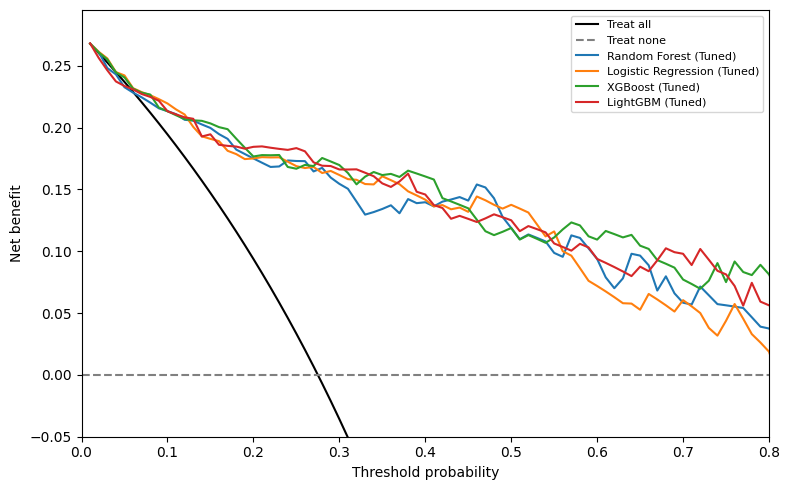

DCA (test set, thresholds 0.01-0.99 step 0.01) saved to results/table_dca_net_benefit.csv


In [ ]:
thr_grid = np.round(np.arange(0.01, 0.991, 0.01), 2)
def decision_curve(y_true, prob, thresholds=thr_grid):
    y_true = np.asarray(y_true); prob = np.asarray(prob); n = len(y_true); rows = []
    for pt in thresholds:
        pred = prob >= pt; tp = np.sum(pred & (y_true == 1)); fp = np.sum(pred & (y_true == 0))
        rows.append((pt, tp/n - (fp/n)*(pt/(1-pt))))
    return pd.DataFrame(rows, columns=['threshold', 'net_benefit'])

dca_tables = {name: decision_curve(y_test, r['y_prob']) for name, r in results.items()}
prev_test = y_test.mean()
dca_reference = pd.DataFrame({'threshold': thr_grid})
dca_reference['treat_all'] = prev_test - (1-prev_test)*(dca_reference['threshold']/(1-dca_reference['threshold']))
dca_reference['treat_none'] = 0.0
dca_wide = dca_reference.copy()
for name, t in dca_tables.items(): dca_wide[name] = t['net_benefit'].values
save(dca_wide, 'table_dca_net_benefit')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dca_wide.threshold, dca_wide.treat_all, 'k-', label='Treat all'); ax.axhline(0, color='grey', ls='--', label='Treat none')
for name in top4: ax.plot(dca_wide.threshold, dca_wide[name], label=name)
ax.set_xlim(0, 0.8); ax.set_ylim(-0.05, prev_test + 0.02); ax.set_xlabel('Threshold probability'); ax.set_ylabel('Net benefit'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figs/fig_dca.png', dpi=180); plt.show()
print('DCA (test set, thresholds 0.01-0.99 step 0.01) saved to results/table_dca_net_benefit.csv')

### 9.5 Subgroup/fairness analysis

Subgroup metrics are calculated on the held-out test set. Small subgroup sizes are reported explicitly and should not be interpreted as definitive fairness evidence.


In [ ]:
# Subgroups from the held-out X_test directly (no index juggling). Selected model, test set.
bp, bpred = results[best_model_name]['y_prob'], results[best_model_name]['y_pred']
sg_masks = {
    'Male': (X_test['Gender'] == 1).values, 'Female': (X_test['Gender'] == 0).values,
    'Infant <=12m': (X_test['Age'] <= 12).values, 'Older >12m': (X_test['Age'] > 12).values,
    'Fully vaccinated': (X_test['Vacc_Full'] == 1).values, 'Not fully vaccinated': (X_test['Vacc_Full'] == 0).values,
}
rows = []
for g, mk_ in sg_masks.items():
    yy = y_test[mk_]; n_pos = int(yy.sum())
    ok = 0 < n_pos < len(yy)
    lo, hi = bootstrap_auc_ci(yy, bp[mk_]) if ok else (np.nan, np.nan)
    rows.append({'Group': g, 'N': int(mk_.sum()), 'N positive': n_pos,
                 'AUC': roc_auc_score(yy, bp[mk_]) if ok else np.nan, 'AUC CI low': lo, 'AUC CI high': hi,
                 'Recall': recall_score(yy, bpred[mk_], zero_division=0) if n_pos else np.nan,
                 'Exploratory (<10 positives)': n_pos < 10})
fairness_results = save(pd.DataFrame(rows), 'table_subgroups')
fairness_results.round(3)

,Group,N,N positive,AUC,AUC CI low,AUC CI high,Recall,Exploratory (<10 positives)
0,Male,102,32,0.911,0.840,0.969,0.719,False
1,Female,58,12,0.815,0.629,0.946,0.583,False
2,Infant <=12m,57,21,0.813,0.687,0.918,0.619,False
3,Older >12m,103,23,0.893,0.788,0.976,0.739,False
4,Fully vaccinated,139,36,0.872,0.795,0.937,0.639,False
5,Not fully vaccinated,21,8,0.952,0.837,1.000,0.875,True


### 9.6 Ten-seed sensitivity analysis

The primary split remains fixed at random seed 42. This analysis repeats the full train/test evaluation using the manuscript's ten seeds.


In [ ]:
# Ten-seed sensitivity using the SELECTED, already-tuned pipelines (hyper-parameters fixed, NOT re-tuned).
SENSITIVITY_SEEDS = [0, 7, 13, 21, 42, 99, 123, 200, 303, 512][:3 if QUICK else 10]
SENS_MODELS = list(dict.fromkeys([best_model_name, 'XGBoost (Tuned)']))
sensitivity_rows = []
for seed in SENSITIVITY_SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    for name in SENS_MODELS:
        m = clone(models[name]); par = {'smote__random_state': seed}
        if 'random_state' in m.named_steps['clf'].get_params(): par['clf__random_state'] = seed
        m.set_params(**par); m.fit(Xtr, ytr)
        sensitivity_rows.append({'Seed': seed, 'Model': name, 'AUC': roc_auc_score(yte, m.predict_proba(Xte)[:, 1])})
sensitivity_results = save(pd.DataFrame(sensitivity_rows), 'table_sensitivity_seeds')
sens_summary = sensitivity_results.groupby('Model')['AUC'].agg(['mean', lambda s: s.std(ddof=1), 'min', 'max']); sens_summary.columns = ['mean', 'sd', 'min', 'max']
save(sens_summary.reset_index(), 'table_sensitivity_summary')
sens_summary.round(4)

,mean,sd,min,max
Model,,,,
Random Forest (Tuned),0.8868,0.0211,0.8564,0.9254
XGBoost (Tuned),0.8834,0.0236,0.8509,0.9279


### 9.7 CERS (Community Exposure Risk Score)

Four community variables (persons/room, smokers at home, vaccination risk 0/0.5/1, household size), min-max scaled with **training** limits. Weights = positive logistic-regression coefficients (L2, C=1) normalised to sum 1. Raw coefficients are reported, so any truncated negative coefficient is visible. Evaluated on train and test against the expert weights.

In [ ]:
def cers_inputs(D):
    return pd.DataFrame({'PPR': D['PersonsPerRoom'], 'Smk': D['SmokersAtHome'],
                         'VR': 0.5*D['Vacc_Partial'] + 1.0*D['Vacc_None'],   # 0 full, 0.5 partial, 1 none
                         'HHS': D['HouseholdSize']})
c_tr, c_te = cers_inputs(X_train), cers_inputs(X_test)           # rows aligned with y_train / y_test
c_imp = SimpleImputer(strategy='median').fit(c_tr)
c_mm = MinMaxScaler().fit(c_imp.transform(c_tr))                 # limits from TRAINING data
Z_tr = c_mm.transform(c_imp.transform(c_tr)); Z_te = np.clip(c_mm.transform(c_imp.transform(c_te)), 0, 1)

cers_lr = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED).fit(Z_tr, y_train)
coef = cers_lr.coef_[0]
w_opt = np.clip(coef, 0, None); w_opt = w_opt / w_opt.sum() if w_opt.sum() > 0 else w_opt
w_exp = np.array([0.35, 0.30, 0.20, 0.15])
cers_weights = pd.DataFrame({'Variable': c_tr.columns, 'LR coefficient (raw)': coef, 'Optimised weight': w_opt, 'Expert weight': w_exp})
cers_weights['Truncated (negative coef)'] = coef < 0
save(cers_weights, 'table_cers_weights')
cers_auc = pd.DataFrame([
    dict(Score='Expert CERS', AUC_train=roc_auc_score(y_train, Z_tr @ w_exp), AUC_test=roc_auc_score(y_test, Z_te @ w_exp)),
    dict(Score='Optimised CERS', AUC_train=roc_auc_score(y_train, Z_tr @ w_opt), AUC_test=roc_auc_score(y_test, Z_te @ w_opt))])
save(cers_auc, 'table_cers_auc')
display(cers_weights.round(4)); display(cers_auc.round(4))

,Variable,LR coefficient (raw),Optimised weight,Expert weight,Truncated (negative coef)
0,PPR,-0.6412,0.0000,0.35,True
1,Smk,0.2969,0.1755,0.30,False
2,VR,1.1812,0.6983,0.20,False
3,HHS,0.2134,0.1262,0.15,False


,Score,AUC_train,AUC_test
0,Expert CERS,0.5422,0.5316
1,Optimised CERS,0.5659,0.5400


### 9.8 CPSS

Derived from a training-set logistic regression on five easily-collected predictors. Points = coefficient / largest |coefficient| x 5, rounded to the nearest 0.5 (predictors that round to 0 add nothing and should be dropped). The legacy published weights are evaluated only for comparison. **Check signs:** wheezing is protective in this dataset, so any score that adds it will invert.

In [ ]:
def cpss_inputs(D, crowd_cut=3.0):          # crowd_cut is an ASSUMPTION - justify or change in the paper
    return pd.DataFrame({'Wheezing': D['Wheezing'], 'Fever': D['Fever'],
                         'Crowding': (D['PersonsPerRoom'] >= crowd_cut).astype(float),
                         'VaccRisk': 0.5*D['Vacc_Partial'] + 1.0*D['Vacc_None'], 'Smoking': D['SmokersAtHome']})
s_tr, s_te = cpss_inputs(X_train), cpss_inputs(X_test)
s_imp = SimpleImputer(strategy='median').fit(s_tr)
S_tr, S_te = s_imp.transform(s_tr), s_imp.transform(s_te)

cp_lr = LogisticRegression(C=1e6, max_iter=2000).fit(S_tr, y_train)        # ~unpenalised
beta = cp_lr.coef_[0]
MAX_POINTS = 5.0                       # largest |coefficient| -> 5 points; tiny coefficients round to 0 (drop them)
points = np.round(beta / np.max(np.abs(beta)) * MAX_POINTS * 2) / 2   # nearest half point
sc_tr, sc_te = S_tr @ points, S_te @ points
cpss_table = pd.DataFrame({'Predictor': s_tr.columns, 'log-odds': beta, 'odds ratio': np.exp(beta), 'Points': points})
save(cpss_table, 'table_cpss_points'); display(cpss_table.round(3))
print('NEGATIVE log-odds / points = protective in THIS dataset (expected for Wheezing).')

# Legacy published weights, for comparison only (same variable definitions as above).
legacy = S_te @ np.array([2.0, 1.5, 1.0, 1.0, 0.5])
cp_auc = roc_auc_score(y_test, sc_te)
cpss_auc = pd.DataFrame([dict(Score='CPSS derived (train)', AUC_train=roc_auc_score(y_train, sc_tr), AUC_test=cp_auc,
                              AUC_test_CI_low=bootstrap_auc_ci(y_test, sc_te)[0], AUC_test_CI_high=bootstrap_auc_ci(y_test, sc_te)[1]),
                         dict(Score='Legacy fixed weights (2,1.5,1,1,0.5)', AUC_train=roc_auc_score(y_train, S_tr @ np.array([2.0, 1.5, 1.0, 1.0, 0.5])),
                              AUC_test=roc_auc_score(y_test, legacy), AUC_test_CI_low=np.nan, AUC_test_CI_high=np.nan)])
save(cpss_auc, 'table_cpss_auc'); display(cpss_auc.round(4))

# Observed pneumonia rate by score (use this to justify any risk bands; do not assert thresholds).
sp = pd.DataFrame({'set': ['train']*len(sc_tr) + ['test']*len(sc_te), 'score': np.r_[sc_tr, sc_te], 'y': np.r_[y_train, y_test]})
cpss_prev = sp.groupby(['set', 'score'])['y'].agg(n='size', n_pos='sum', prevalence='mean').reset_index()
save(cpss_prev, 'table_cpss_score_prevalence'); cpss_prev

,Predictor,log-odds,odds ratio,Points
0,Wheezing,-2.352,0.095,-5.0
1,Fever,1.139,3.124,2.5
2,Crowding,-0.041,0.960,-0.0
3,VaccRisk,1.795,6.018,4.0
4,Smoking,0.400,1.492,1.0


NEGATIVE log-odds / points = protective in THIS dataset (expected for Wheezing).


,Score,AUC_train,AUC_test,AUC_test_CI_low,AUC_test_CI_high
0,CPSS derived (train),0.8271,0.8475,0.7707,0.9153
1,"Legacy fixed weights (2,1.5,1,1,0.5)",0.3415,0.2745,NaN,NaN


,set,score,n,n_pos,prevalence
0,test,-5.0,28,2,0.071429
1,test,-4.0,17,2,0.117647
2,test,-3.0,3,0,0.000000
3,test,-2.5,34,2,0.058824
4,test,-2.0,1,0,0.000000
5,test,-1.5,17,1,0.058824
6,test,-0.5,6,3,0.500000
7,test,0.0,4,2,0.500000
8,test,0.5,5,0,0.000000
9,test,1.0,2,1,0.500000


In [ ]:
# 9.9 Hospital model vs community-level (CHW-available) model.
# CHW list excludes lab tests, chest X-ray, auscultation (crackles) and pulse oximetry. Review with your clinical co-author.
CHW_FEATURES = ['Age','Gender','Siblings','Prematurity','Breastfed','PriorRespAdm','Temperature','RespiratoryRate','Fever','Wheezing',
                'NasalFlaring','Cyanosis','HouseholdSize','Rooms','PersonsPerRoom','SmokersAtHome','VitaminA',
                'Vacc_Full','Vacc_Partial','Vacc_None','HibDoses','PneumoDoses']
assert all(c in FEATURE_COLS for c in CHW_FEATURES)
rows = []
for name in dict.fromkeys([best_model_name, 'Logistic Regression (Tuned)']):
    full_cv = cv_summary(cross_val_score(clone(models[name]), X_train, y_train, cv=cv_outer, scoring='roc_auc', n_jobs=-1))
    chw_cv = cv_summary(cross_val_score(clone(models[name]), X_train[CHW_FEATURES], y_train, cv=cv_outer, scoring='roc_auc', n_jobs=-1))
    m = clone(models[name]).fit(X_train[CHW_FEATURES], y_train); p = m.predict_proba(X_test[CHW_FEATURES])[:, 1]
    lo, hi = bootstrap_auc_ci(y_test, p)
    rows.append(dict(Model=name, Full_CV_AUC=full_cv['mean'], CHW_CV_AUC=chw_cv['mean'], CHW_test_AUC=roc_auc_score(y_test, p), CHW_test_CI_low=lo, CHW_test_CI_high=hi))
chw_results = save(pd.DataFrame(rows), 'table_hospital_vs_chw'); chw_results.round(4)

,Model,Full_CV_AUC,CHW_CV_AUC,CHW_test_AUC,CHW_test_CI_low,CHW_test_CI_high
0,Random Forest (Tuned),0.8833,0.8543,0.8536,0.7854,0.9165
1,Logistic Regression (Tuned),0.8770,0.8475,0.8305,0.7569,0.9005


## 10. Figures

Publication-ready figures: ROC curves, CV-AUC with confidence intervals, feature
importance, confusion matrices, SHAP summary, vaccination prevalence, and
household-crowding analysis.

In [ ]:
BLUE, GOLD, RED, GREEN = '#1a3a5c', '#e8a020', '#c0392b', '#27ae60'
COLORS = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd',
          '#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf','#aec7e8']

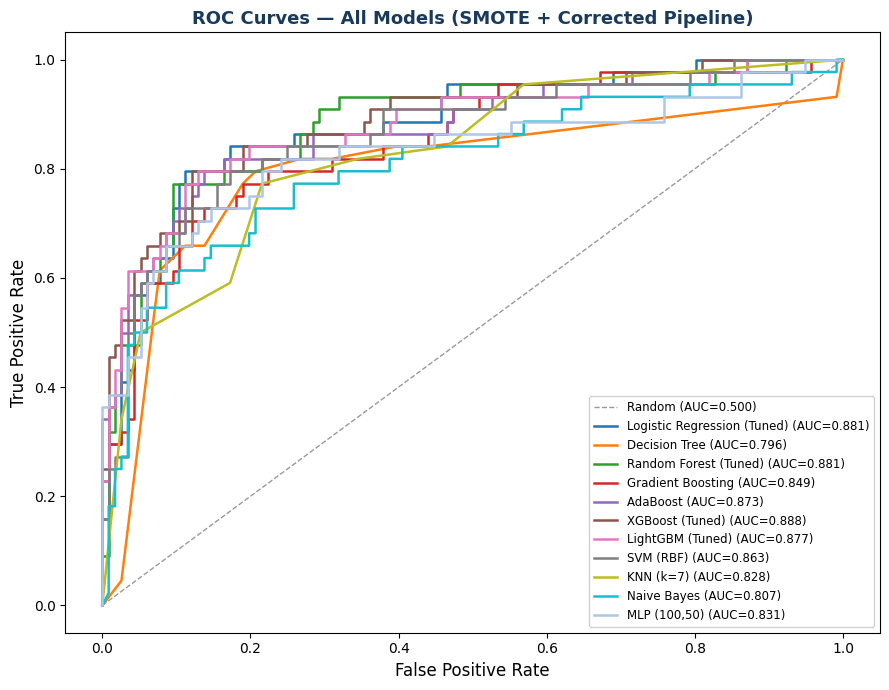

In [ ]:
# ── Fig 1: ROC Curves ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0,1],[0,1],'k--', alpha=0.4, lw=1, label='Random (AUC=0.500)')
for (name, res), col in zip(results.items(), COLORS):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"{name} (AUC={res['AUC-ROC']:.3f})")
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves \u2014 All Models (SMOTE + Corrected Pipeline)', fontsize=13, fontweight='bold', color=BLUE)
ax.legend(loc='lower right', fontsize=8.5, framealpha=0.9)
plt.tight_layout()
plt.savefig('figs/fig1_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

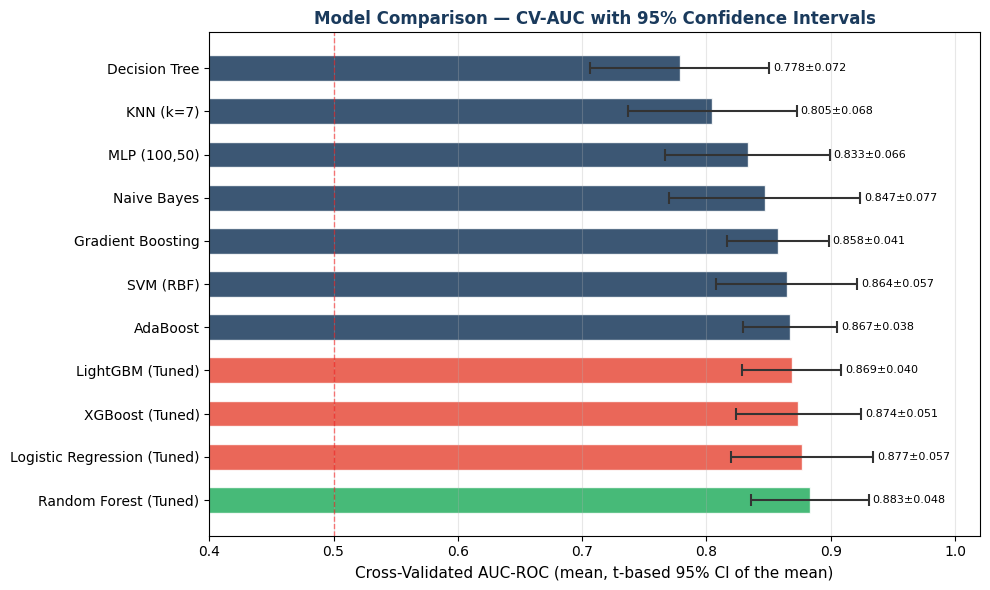

In [ ]:
# ── Fig 2: CV-AUC with 95% confidence intervals ────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
names_sorted = sorted(results.keys(), key=lambda n: results[n]['CV-AUC Mean'], reverse=True)
means = [results[n]['CV-AUC Mean'] for n in names_sorted]
stds  = [results[n]['CV-AUC Std']  for n in names_sorted]
ci95  = [results[n]['CV-AUC CI half'] for n in names_sorted]  # t-based 95% CI of the mean
colors_bar = [GREEN if m == max(means) else ('#e74c3c' if '(Tuned)' in n else BLUE)
              for m, n in zip(means, names_sorted)]

ax.barh(range(len(names_sorted)), means, xerr=ci95, color=colors_bar, alpha=0.85,
        edgecolor='white', height=0.6,
        error_kw={'elinewidth':1.5, 'capsize':4, 'capthick':1.5, 'ecolor':'#333'})
ax.set_yticks(range(len(names_sorted)))
ax.set_yticklabels(names_sorted, fontsize=10)
ax.set_xlabel('Cross-Validated AUC-ROC (mean, t-based 95% CI of the mean)', fontsize=11)
ax.set_title('Model Comparison \u2014 CV-AUC with 95% Confidence Intervals', fontsize=12, fontweight='bold', color=BLUE)
ax.axvline(0.5, color='red', lw=1, linestyle='--', alpha=0.5)
for i, (m, c) in enumerate(zip(means, ci95)):
    ax.text(m + c + 0.003, i, f'{m:.3f}\u00b1{c:.3f}', va='center', fontsize=8)
ax.set_xlim(0.4, 1.02)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig2_cv_auc_ci.png', dpi=180, bbox_inches='tight')
plt.show()

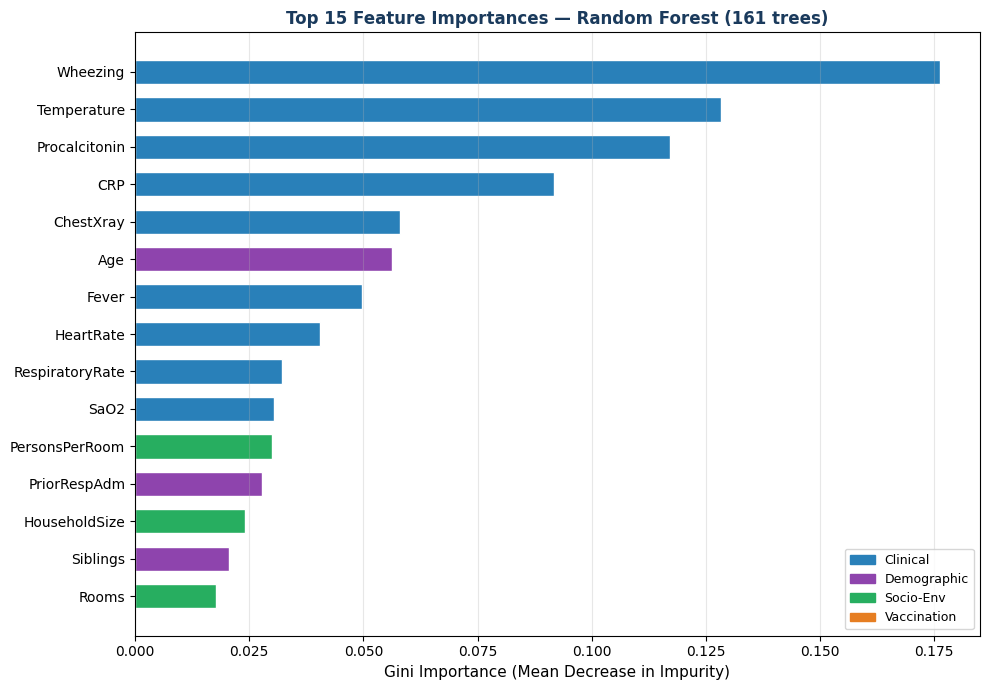

In [ ]:
# ── Fig 3: Feature Importance (top 15, color-coded by category) ────────────
cats = {'CRP':'Clinical','Procalcitonin':'Clinical','SaO2':'Clinical',
        'Temperature':'Clinical','RespiratoryRate':'Clinical','HeartRate':'Clinical',
        'Fever':'Clinical','Crackles':'Clinical','Wheezing':'Clinical',
        'NasalFlaring':'Clinical','Cyanosis':'Clinical', 'ChestXray':'Clinical',
        'Age':'Demographic','Gender':'Demographic','Siblings':'Demographic',
        'Prematurity':'Demographic','Breastfed':'Demographic','PriorRespAdm':'Demographic',
        'HouseholdSize':'Socio-Env','Rooms':'Socio-Env','PersonsPerRoom':'Socio-Env',
        'SmokersAtHome':'Socio-Env','VitaminA':'Socio-Env',
        'Vacc_Full':'Vaccination','Vacc_Partial':'Vaccination','Vacc_None':'Vaccination',
        'HibDoses':'Vaccination','PneumoDoses':'Vaccination'}
cat_colors = {'Clinical':'#2980b9','Demographic':'#8e44ad','Socio-Env':'#27ae60','Vaccination':'#e67e22'}

top_n = 15
fi_top = feat_imp.head(top_n)
bar_colors = [cat_colors.get(cats.get(f,'Clinical'),'#555') for f in fi_top['Feature']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(fi_top)), fi_top['Importance'].values, color=bar_colors, edgecolor='white', height=0.65)
ax.set_yticks(range(len(fi_top)))
ax.set_yticklabels(fi_top['Feature'].values, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel('Gini Importance (Mean Decrease in Impurity)', fontsize=11)
ax.set_title(f'Top {top_n} Feature Importances \u2014 Random Forest ({rf_clf.get_params()["n_estimators"]} trees)', fontsize=12, fontweight='bold', color=BLUE)
patches = [mpatches.Patch(color=c, label=l) for l, c in cat_colors.items()]
ax.legend(handles=patches, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig3_feature_importance.png', dpi=180, bbox_inches='tight')
plt.show()

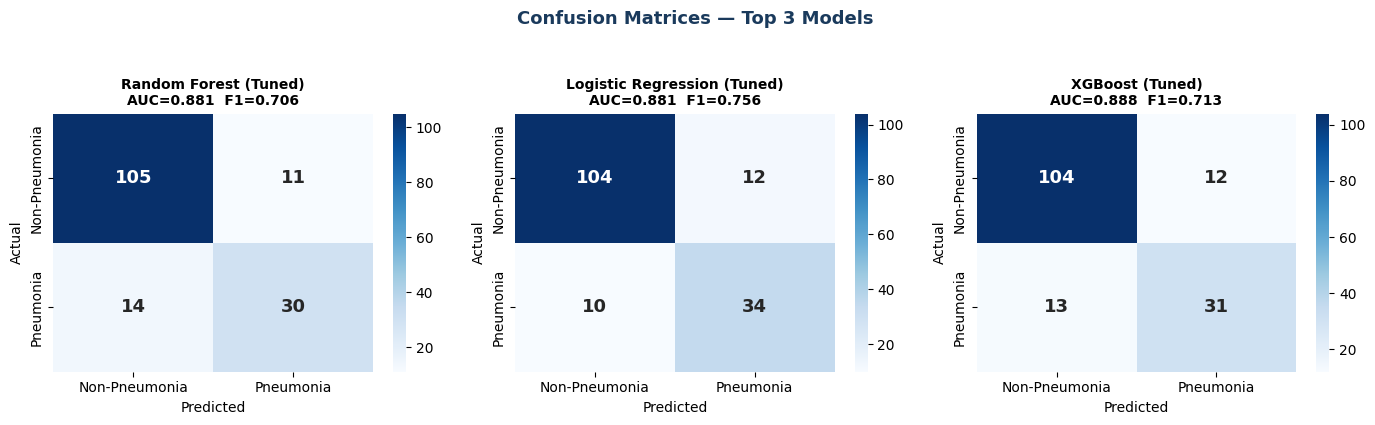

In [ ]:
# ── Fig 4: Confusion matrices (top 3 models) ────────────────────────────────
top3 = sorted(results.keys(), key=lambda n: results[n]['CV-AUC Mean'], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, top3):
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Pneumonia','Pneumonia'],
                yticklabels=['Non-Pneumonia','Pneumonia'],
                annot_kws={'size':13, 'weight':'bold'})
    ax.set_title(f'{name}\nAUC={results[name]["AUC-ROC"]:.3f}  F1={results[name]["F1"]:.3f}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)
fig.suptitle('Confusion Matrices \u2014 Top 3 Models', fontsize=13, fontweight='bold', color=BLUE, y=1.05)
plt.tight_layout()
plt.savefig('figs/fig4_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

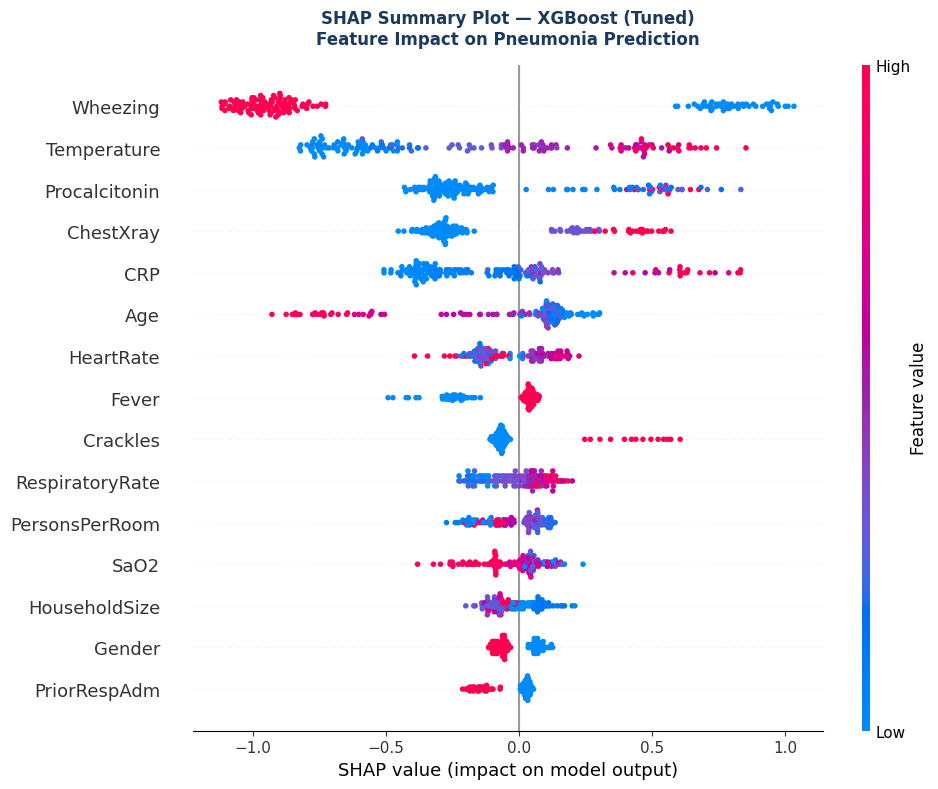

In [ ]:
# ── Fig 5: SHAP Summary Plot ────────────────────────────────────────────────
shap.summary_plot(shap_vals, Xtest_transformed, feature_names=FEATURE_COLS,
                  max_display=15, show=False, plot_size=(10, 8))
plt.title('SHAP Summary Plot \u2014 XGBoost (Tuned)\nFeature Impact on Pneumonia Prediction',
          fontsize=12, fontweight='bold', color=BLUE, pad=15)
plt.tight_layout()
plt.savefig('figs/fig5_shap_summary.png', dpi=180, bbox_inches='tight')
plt.show()

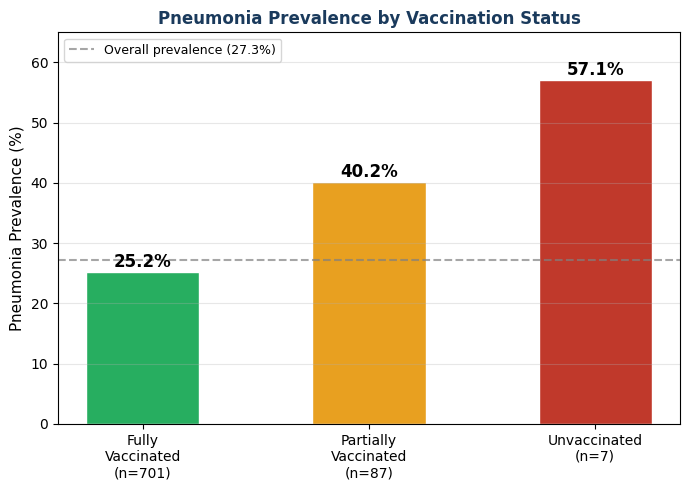

In [ ]:
# ── Fig 6: Pneumonia prevalence by vaccination status ──────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
labels = [f"Fully\nVaccinated\n(n={vax_prev['Full'][1]})",
          f"Partially\nVaccinated\n(n={vax_prev['Partial'][1]})",
          f"Unvaccinated\n(n={vax_prev['None'][1]})"]
prevs  = [vax_prev['Full'][0]*100, vax_prev['Partial'][0]*100, vax_prev['None'][0]*100]
bars = ax.bar(labels, prevs, color=[GREEN, GOLD, RED], edgecolor='white', width=0.5)
for bar, val in zip(bars, prevs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.8,
            f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Pneumonia Prevalence (%)', fontsize=11)
ax.set_title('Pneumonia Prevalence by Vaccination Status', fontsize=12, fontweight='bold', color=BLUE)
ax.set_ylim(0, 65)
ax.axhline(feat['target'].mean()*100, color='grey', lw=1.5, linestyle='--', alpha=0.7,
           label=f"Overall prevalence ({feat['target'].mean()*100:.1f}%)")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('figs/fig6_vaccination_prevalence.png', dpi=180, bbox_inches='tight')
plt.show()

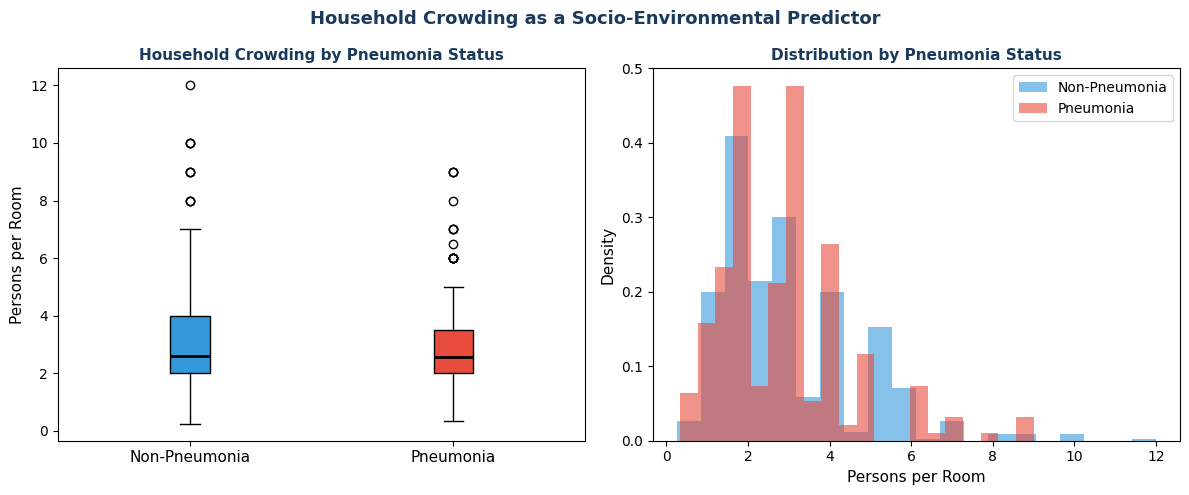

In [ ]:
# ── Fig 7: Household crowding analysis ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
data0 = feat.loc[feat['target']==0, 'PersonsPerRoom'].dropna()
data1 = feat.loc[feat['target']==1, 'PersonsPerRoom'].dropna()
bp = ax.boxplot([data0, data1], patch_artist=True, medianprops={'color':'black','linewidth':2})
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
ax.set_xticklabels(['Non-Pneumonia', 'Pneumonia'], fontsize=11)
ax.set_ylabel('Persons per Room', fontsize=11)
ax.set_title('Household Crowding by Pneumonia Status', fontsize=11, fontweight='bold', color=BLUE)

ax2 = axes[1]
ax2.hist(data0, bins=20, alpha=0.6, color='#3498db', label='Non-Pneumonia', density=True)
ax2.hist(data1, bins=20, alpha=0.6, color='#e74c3c', label='Pneumonia', density=True)
ax2.set_xlabel('Persons per Room', fontsize=11)
ax2.set_ylabel('Density', fontsize=11)
ax2.set_title('Distribution by Pneumonia Status', fontsize=11, fontweight='bold', color=BLUE)
ax2.legend(fontsize=10)

fig.suptitle('Household Crowding as a Socio-Environmental Predictor', fontsize=13, fontweight='bold', color=BLUE)
plt.tight_layout()
plt.savefig('figs/fig7_crowding_analysis.png', dpi=180, bbox_inches='tight')
plt.show()

## 10b. Additional figures for the manuscript

Calibration curves, DeLong/McNemar heat maps, SHAP dependence and individual explanations, exposure-score and points-score figures, subgroup forest plot, ten-seed sensitivity, and ablation / community-level comparison. Every figure is computed from this run (nothing hard-coded) and saved to `figs/` at 300 dpi.

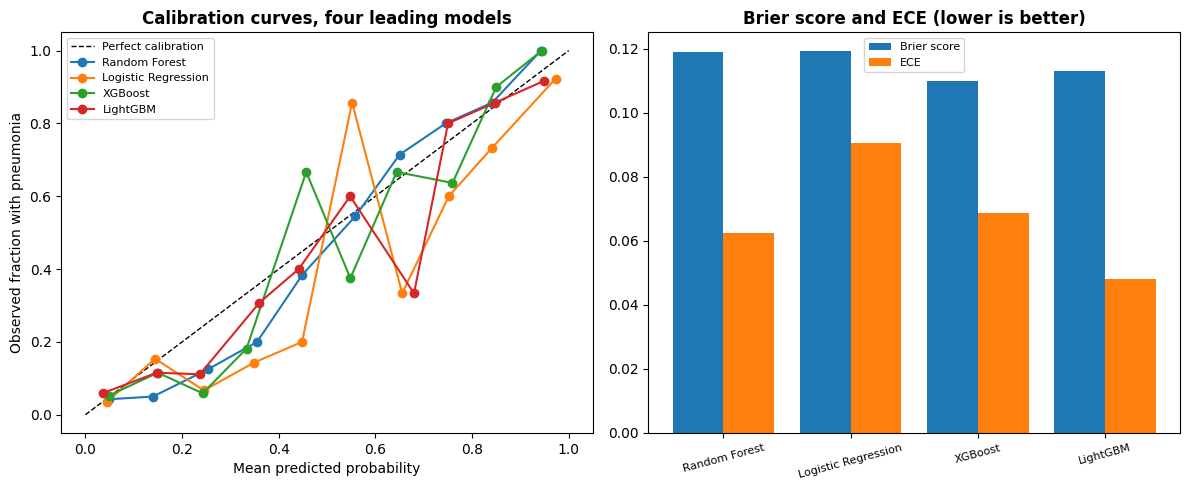

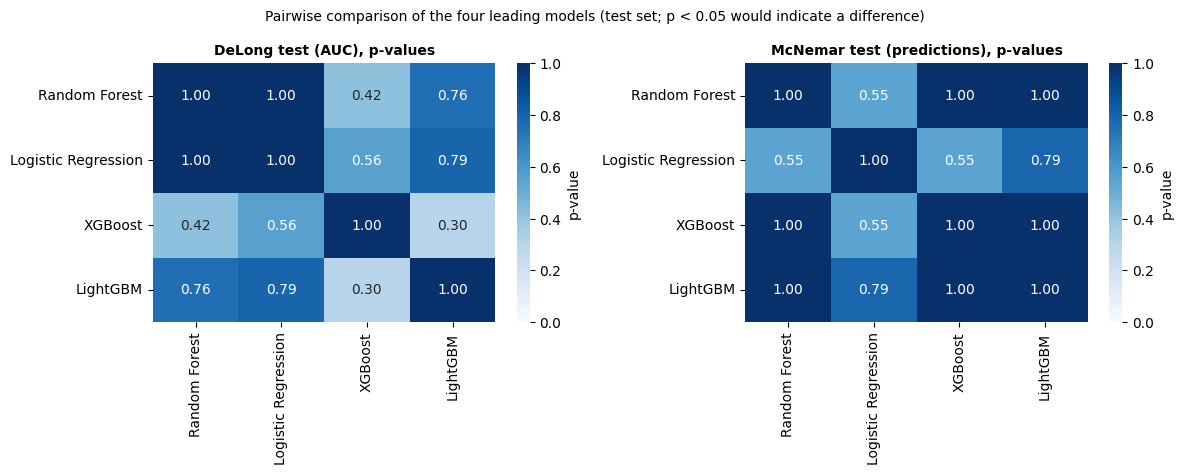

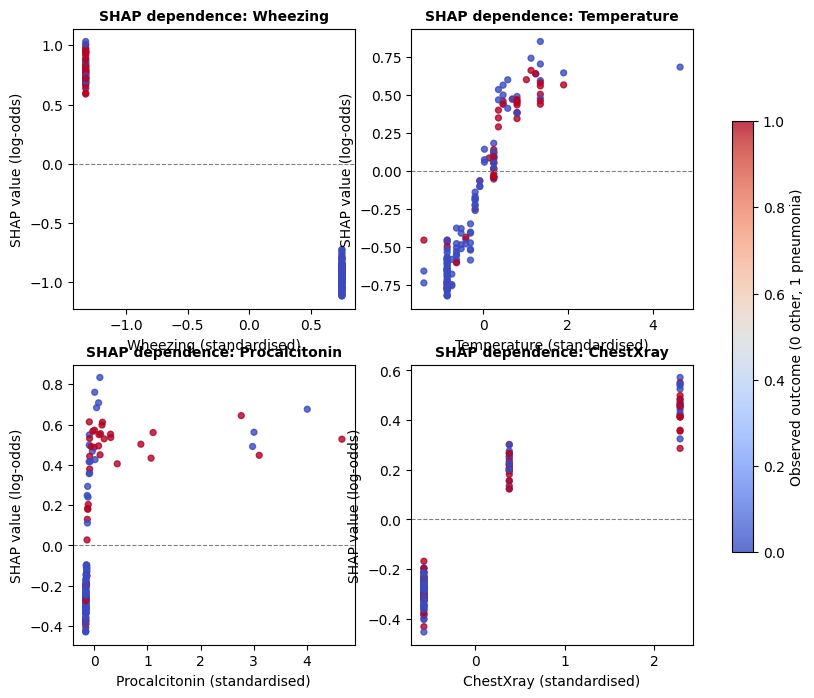

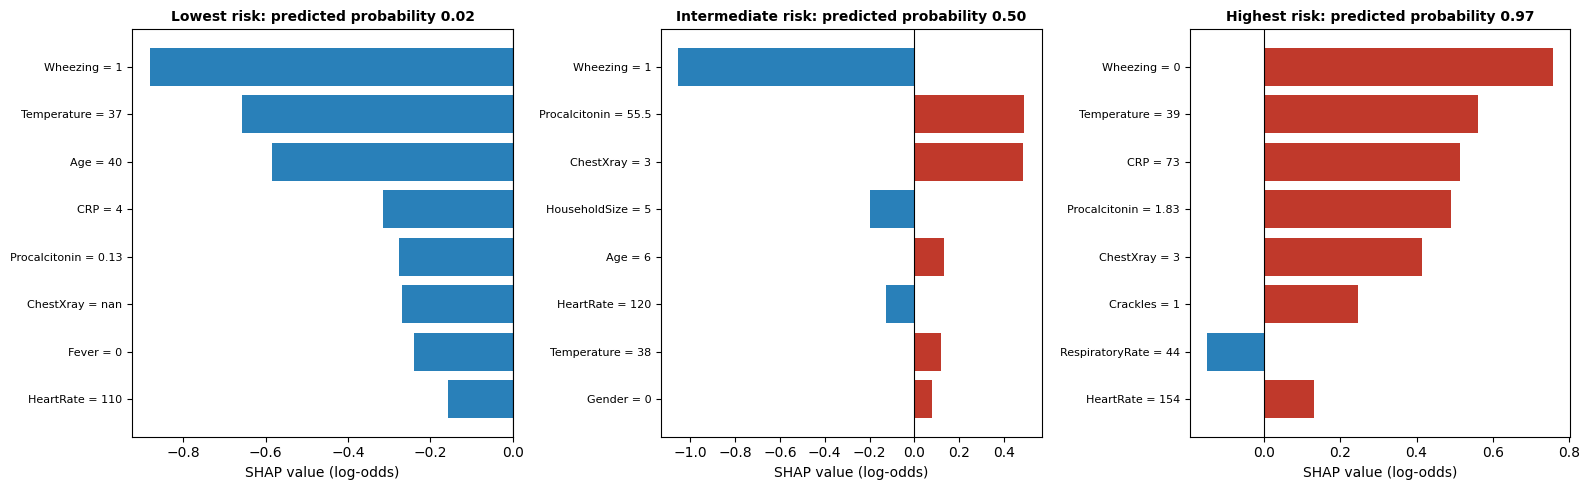

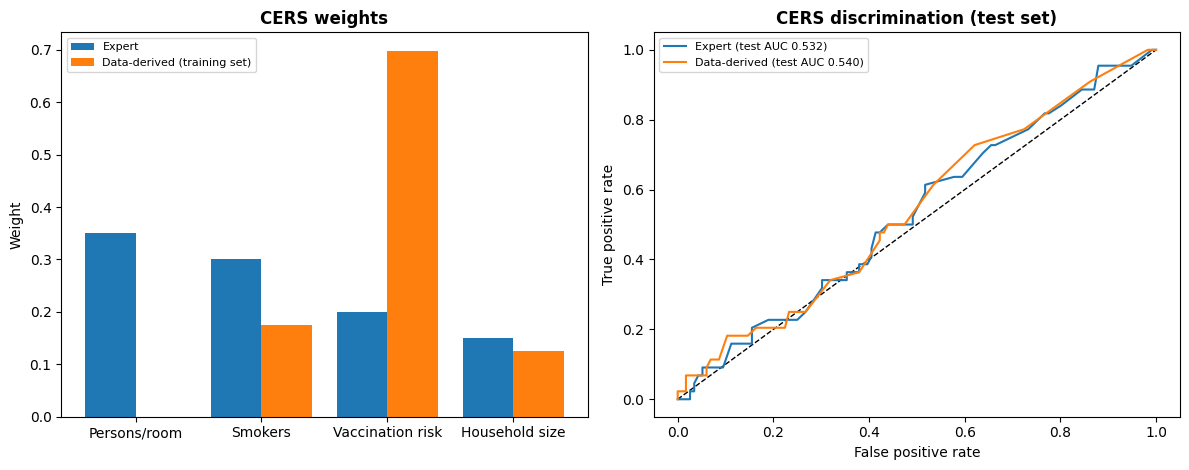

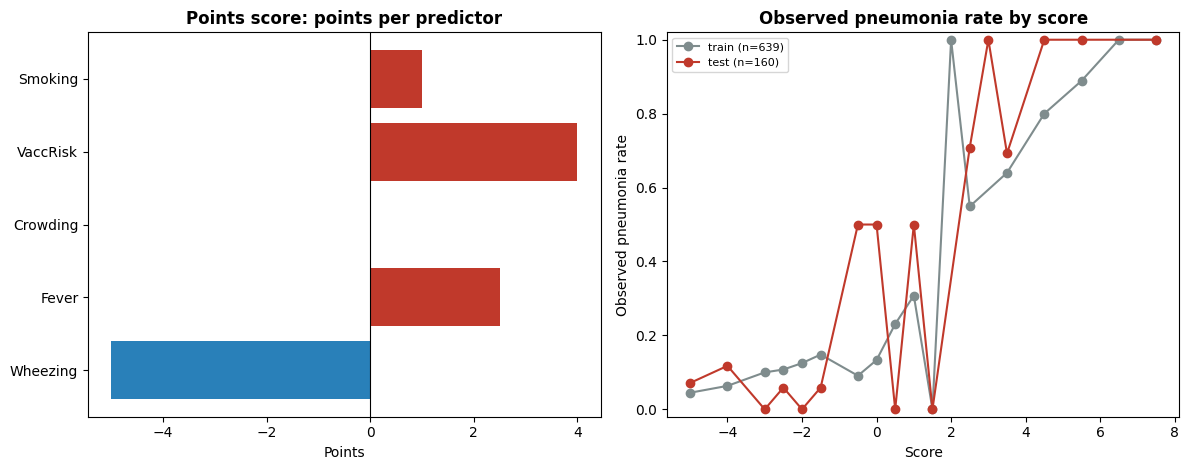

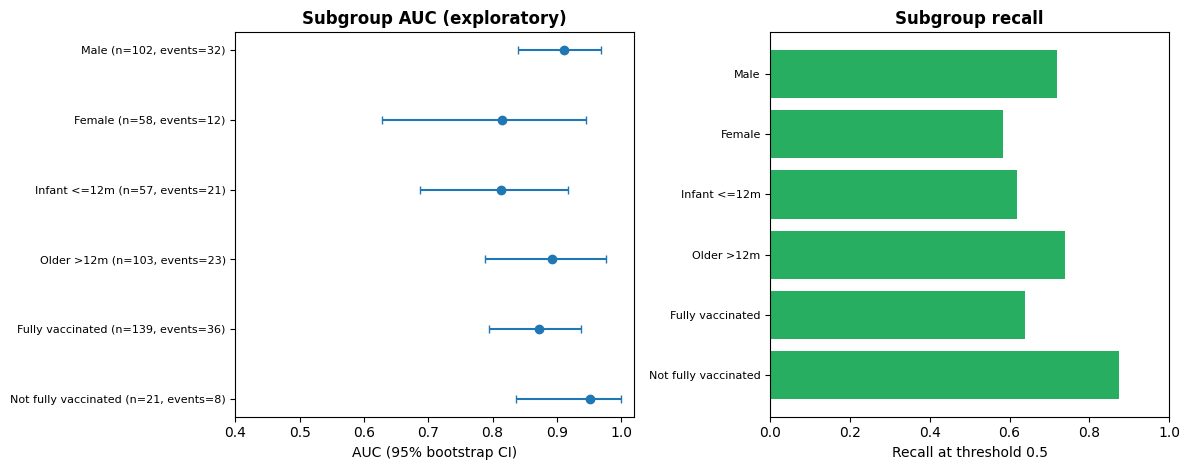

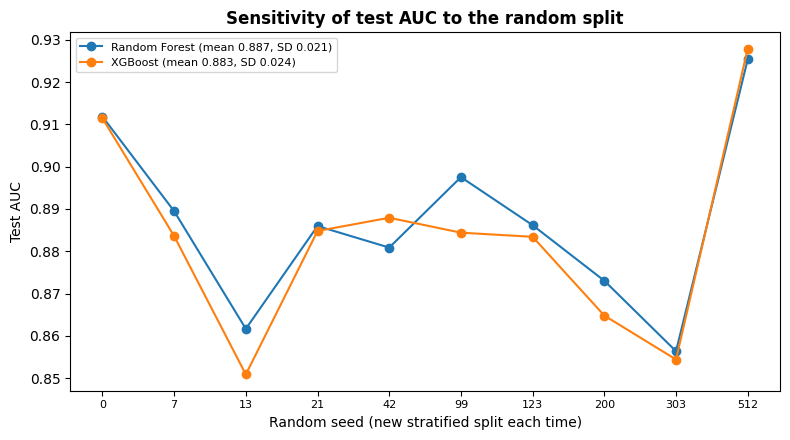

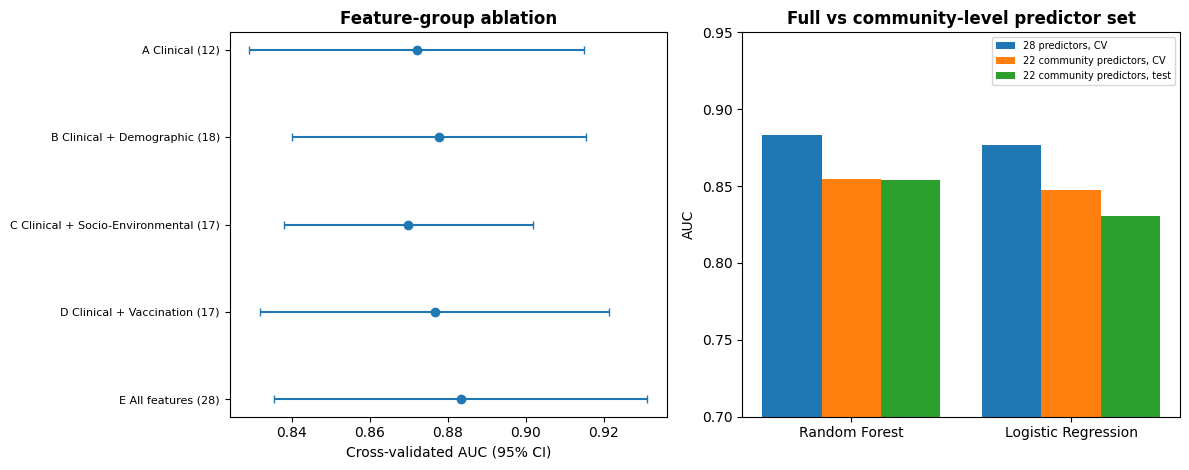

Saved figA..figI to figs/


In [ ]:
# 10b. Additional figures (all computed from this run's objects)
short = lambda s: s.replace(' (Tuned)', '')
DPI = 300

# ---- Fig A: calibration curves + Brier / ECE (test set, raw probabilities, 10 uniform bins)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]; ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
for name in top4:
    frac, mean_p = calibration_curve(y_test, results[name]['y_prob'], n_bins=10, strategy='uniform')
    ax.plot(mean_p, frac, marker='o', lw=1.5, label=short(name))
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed fraction with pneumonia')
ax.set_title('Calibration curves, four leading models', fontweight='bold'); ax.legend(fontsize=8)
cal4 = calibration_results.set_index('Model').loc[top4]
x = np.arange(len(top4)); ax = axes[1]
ax.bar(x - 0.2, cal4['Brier'], 0.4, label='Brier score'); ax.bar(x + 0.2, cal4['ECE'], 0.4, label='ECE')
ax.set_xticks(x); ax.set_xticklabels([short(n) for n in top4], fontsize=8, rotation=15)
ax.set_title('Brier score and ECE (lower is better)', fontweight='bold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figs/figA_calibration.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig B: DeLong and McNemar p-value heat maps (four leading models)
def pmat(col):
    M = pd.DataFrame(1.0, index=top4, columns=top4)
    for _, r in pairwise_tests.iterrows():
        M.loc[r['model_1'], r['model_2']] = M.loc[r['model_2'], r['model_1']] = r[col]
    M.index = M.columns = [short(n) for n in top4]; return M
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, col, ttl in zip(axes, ['delong_p', 'mcnemar_p'], ['DeLong test (AUC), p-values', 'McNemar test (predictions), p-values']):
    sns.heatmap(pmat(col), annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues', cbar_kws={'label': 'p-value'}, ax=ax)
    ax.set_title(ttl, fontweight='bold', fontsize=10)
plt.suptitle('Pairwise comparison of the four leading models (test set; p < 0.05 would indicate a difference)', fontsize=10)
plt.tight_layout(); plt.savefig('figs/figB_delong_mcnemar.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig C: SHAP dependence for the four most influential predictors (XGBoost, test set)
top_feats = shap_dir['feature'].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, f in zip(axes.ravel(), top_feats):
    j = FEATURE_COLS.index(f)
    sc = ax.scatter(Xtest_transformed[:, j], shap_vals[:, j], c=y_test, cmap='coolwarm', s=18, alpha=0.8)
    ax.axhline(0, color='grey', lw=0.8, ls='--'); ax.set_xlabel(f + ' (standardised)'); ax.set_ylabel('SHAP value (log-odds)')
    ax.set_title('SHAP dependence: ' + f, fontweight='bold', fontsize=10)
fig.colorbar(sc, ax=axes, label='Observed outcome (0 other, 1 pneumonia)', shrink=0.7)
plt.savefig('figs/figC_shap_dependence.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig D: individual explanations (lowest, closest-to-0.5, highest predicted risk), XGBoost
p_x = xgb_pipe.predict_proba(X_test)[:, 1]
picks = [('Lowest risk', int(np.argmin(p_x))), ('Intermediate risk', int(np.argmin(np.abs(p_x - 0.5)))), ('Highest risk', int(np.argmax(p_x)))]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (ttl, i) in zip(axes, picks):
    order = np.argsort(-np.abs(shap_vals[i]))[:8][::-1]
    vals = shap_vals[i, order]
    labels = [f"{FEATURE_COLS[j]} = {X_test.iloc[i, j]:.3g}" for j in order]
    ax.barh(range(len(order)), vals, color=['#c0392b' if v > 0 else '#2980b9' for v in vals])
    ax.set_yticks(range(len(order))); ax.set_yticklabels(labels, fontsize=8); ax.axvline(0, color='k', lw=0.8)
    ax.set_title(f"{ttl}: predicted probability {p_x[i]:.2f}", fontweight='bold', fontsize=10); ax.set_xlabel('SHAP value (log-odds)')
plt.tight_layout(); plt.savefig('figs/figD_shap_individual.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig E: community exposure score (weights and test ROC)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8)); ax = axes[0]
x = np.arange(len(cers_weights)); ax.bar(x - 0.2, cers_weights['Expert weight'], 0.4, label='Expert')
ax.bar(x + 0.2, cers_weights['Optimised weight'], 0.4, label='Data-derived (training set)')
ax.set_xticks(x); ax.set_xticklabels(['Persons/room', 'Smokers', 'Vaccination risk', 'Household size']); ax.set_ylabel('Weight'); ax.legend(fontsize=8)
ax.set_title('CERS weights', fontweight='bold')
ax = axes[1]; ax.plot([0, 1], [0, 1], 'k--', lw=1)
for lab, w in [('Expert', w_exp), ('Data-derived', w_opt)]:
    fpr, tpr, _ = roc_curve(y_test, Z_te @ w); ax.plot(fpr, tpr, label=f"{lab} (test AUC {roc_auc_score(y_test, Z_te @ w):.3f})")
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(fontsize=8); ax.set_title('CERS discrimination (test set)', fontweight='bold')
plt.tight_layout(); plt.savefig('figs/figE_cers.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig F: points score (points per predictor; observed pneumonia rate by score)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8)); ax = axes[0]
ax.barh(cpss_table['Predictor'], cpss_table['Points'], color=['#c0392b' if v > 0 else '#2980b9' for v in cpss_table['Points']])
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('Points'); ax.set_title('Points score: points per predictor', fontweight='bold')
ax = axes[1]
for s_, col in [('train', '#7f8c8d'), ('test', '#c0392b')]:
    d = cpss_prev[cpss_prev['set'] == s_]; ax.plot(d['score'], d['prevalence'], marker='o', color=col, label=f"{s_} (n={int(d['n'].sum())})")
ax.set_xlabel('Score'); ax.set_ylabel('Observed pneumonia rate'); ax.set_ylim(-0.02, 1.02); ax.legend(fontsize=8)
ax.set_title('Observed pneumonia rate by score', fontweight='bold')
plt.tight_layout(); plt.savefig('figs/figF_points_score.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig G: subgroup AUC (bootstrap CI) and recall, selected model
fr = fairness_results.copy(); fig, axes = plt.subplots(1, 2, figsize=(12, 4.8)); ax = axes[0]
yy = np.arange(len(fr))[::-1]; ok = fr['AUC'].notna()
ax.errorbar(fr.loc[ok, 'AUC'], yy[ok.values], xerr=[fr.loc[ok, 'AUC'] - fr.loc[ok, 'AUC CI low'], fr.loc[ok, 'AUC CI high'] - fr.loc[ok, 'AUC']], fmt='o', capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{g} (n={n}, events={e})" for g, n, e in zip(fr['Group'], fr['N'], fr['N positive'])], fontsize=8)
ax.set_xlabel('AUC (95% bootstrap CI)'); ax.set_xlim(0.4, 1.02); ax.set_title('Subgroup AUC (exploratory)', fontweight='bold')
ax = axes[1]; ax.barh(yy, fr['Recall'], color='#27ae60'); ax.set_yticks(yy); ax.set_yticklabels(fr['Group'], fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel('Recall at threshold 0.5'); ax.set_title('Subgroup recall', fontweight='bold')
plt.tight_layout(); plt.savefig('figs/figG_subgroups.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig H: ten-seed sensitivity
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, d in sensitivity_results.groupby('Model'):
    ax.plot(range(len(d)), d['AUC'].values, marker='o', label=f"{short(name)} (mean {d['AUC'].mean():.3f}, SD {d['AUC'].std(ddof=1):.3f})")
ax.set_xticks(range(len(SENSITIVITY_SEEDS))); ax.set_xticklabels(SENSITIVITY_SEEDS, fontsize=8)
ax.set_xlabel('Random seed (new stratified split each time)'); ax.set_ylabel('Test AUC'); ax.legend(fontsize=8)
ax.set_title('Sensitivity of test AUC to the random split', fontweight='bold')
plt.tight_layout(); plt.savefig('figs/figH_sensitivity.png', dpi=DPI, bbox_inches='tight'); plt.show()

# ---- Fig I: ablation (CV-AUC with CI) and full vs community-level predictor sets
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8)); ax = axes[0]
ab = ablation_results; yy = np.arange(len(ab))[::-1]
ax.errorbar(ab['CV-AUC mean'], yy, xerr=[ab['CV-AUC mean'] - ab['CI low'], ab['CI high'] - ab['CV-AUC mean']], fmt='o', capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{a} ({k})" for a, k in zip(ab['Feature set'], ab['N features'])], fontsize=8)
ax.set_xlabel('Cross-validated AUC (95% CI)'); ax.set_title('Feature-group ablation', fontweight='bold')
ax = axes[1]; cw = chw_results; x = np.arange(len(cw)); w_ = 0.27
ax.bar(x - w_, cw['Full_CV_AUC'], w_, label='28 predictors, CV'); ax.bar(x, cw['CHW_CV_AUC'], w_, label='22 community predictors, CV')
ax.bar(x + w_, cw['CHW_test_AUC'], w_, label='22 community predictors, test')
ax.set_xticks(x); ax.set_xticklabels([short(n) for n in cw['Model']]); ax.set_ylim(0.7, 0.95); ax.set_ylabel('AUC'); ax.legend(fontsize=7)
ax.set_title('Full vs community-level predictor set', fontweight='bold')
plt.tight_layout(); plt.savefig('figs/figI_ablation_community.png', dpi=DPI, bbox_inches='tight'); plt.show()
print('Saved figA..figI to figs/')

## 11. Save Results

In [ ]:
run_log = {
    'versions': VERSIONS, 'seed': SEED, 'quick_mode': QUICK, 'n_boot': N_BOOT,
    'dataset': {'n_total': int(feat.shape[0]), 'n_features': len(FEATURE_COLS), 'n_pos': int(feat['target'].sum()),
                'n_neg': int((feat['target'] == 0).sum()), 'pos_rate': float(feat['target'].mean())},
    'split': SPLIT, 'selected_model': best_model_name, 'top4_by_cv': top4,
    'best_params': {n: {k.replace('clf__', ''): (v.item() if hasattr(v, 'item') else v) for k, v in s_.best_params_.items()}
                    for n, s_ in SEARCHES.items()},
}
with open('results/run_log.json', 'w') as f:
    json.dump(run_log, f, indent=2, default=str)
if QUICK: print('QUICK MODE: these numbers are for a smoke test only - do NOT use them in the paper.')
print('Selected model:', best_model_name, '| CV-AUC:', round(results[best_model_name]['CV-AUC Mean'], 4))
print('All tables written to results/ ; figures in figs/ ; log in results/run_log.json')

Selected model: Random Forest (Tuned) | CV-AUC: 0.8832
All tables written to results/ ; figures in figs/ ; log in results/run_log.json
